# Predictive Modeling Project for FinMark



##Project Objective
The goal of this project is to develop a predictive machine learning model that estimates the likelihood of a customer making a purchase within a defined future period. By shifting from manual, rule‑based assessments to a data‑driven predictive approach, FinMark can better understand customer behavior, anticipate purchasing intent, and make more informed decisions about marketing and outreach strategies.

##Business Need

FinMark currently relies on manual review and simple heuristics to identify potential buyers. This approach becomes less effective as the customer base grows because:
- it does not scale efficiently
- it may overlook complex behavioral patterns
- it treats all customers similarly, regardless of their engagement history
- it limits the ability to prioritize high‑intent customers

A predictive model addresses these limitations by quantifying customer behavior and identifying patterns that are not easily visible through manual analysis. This allows FinMark to:
- focus marketing resources on customers most likely to convert
- design targeted campaigns based on behavioral segments
- improve customer engagement strategies
- reduce wasted outreach efforts

The model ultimately supports more efficient decision‑making and helps FinMark allocate time and resources where they will have the greatest impact.

##Problem and Need Identification

The core problem is that FinMark lacks a scalable, data‑driven method for identifying which customers are most likely to make a purchase in the near future. Without this capability, the company risks:
- missing opportunities with high‑intent customers
- overspending on low‑probability leads
- failing to recognize early signs of disengagement
- relying on incomplete or inconsistent information

To address this, the project must clearly define:
- the target behavior to predict
- the data sources needed to understand customer activity
- the key requirements for building a reliable model
- the constraints and limitations of the available data

A successful solution requires not only technical accuracy but also a clear understanding of user needs and business constraints. The model must provide insights that FinMark can act on, and the analysis must consider the consequences of different modeling choices, especially when dealing with incomplete or imbalanced data.


##Solution Overview
The solution involves integrating multiple datasets: transactions, products, and customer profiles, to create a comprehensive view of customer behavior. Through data cleaning, exploratory analysis, and feature engineering, the project constructs meaningful behavioral indicators such as frequency, recency, consistency, and monetary value. These features form the foundation of a predictive model that estimates purchase likelihood.

Beyond the technical implementation, the solution also considers:
- how the model’s predictions will be used in real decision‑making
- what insights the model reveals about customer behavior
- how FinMark can adjust marketing strategies based on these insights
- what risks or limitations must be acknowledged before deployment

##Data Sources, Data Understanding, and Data Quality Assessment

In [ ]:
#Step 1 - Import libraries
import pandas as pd      #For data loading, cleaning, and tabular manipulation
import numpy as np       #For numerical operations and array-based computations
from dateutil import parser      #For flexible parsing of date and time values
import re      #For text pattern matching and preprocessing
import matplotlib.pyplot as plt       #For data visualization and exploratory analysis
import seaborn as sns       #For data visualization and exploratory analysis

In [ ]:
#Step 2 - Mount Google Drive and load the datasets from MyDrive

from google.colab import drive
drive.mount('/content/drive')

#The following datasets are used to capture different aspects of the business, including transaction history, product information, and customer attributes.
transactions_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/transactions_data.csv'
products_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/products_data.csv'
customers_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/customers_data.csv'

# Load the datasets
transactions_df = pd.read_csv(transactions_path)
products_df = pd.read_csv(products_path)
customers_df = pd.read_csv(customers_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Data Sources**

The project integrates three datasets: transactions, products, and customers, to build a comprehensive view of purchasing behavior. Each dataset contributes a different layer of information:
- Transaction data captures historical purchasing activity, including quantities, prices, and dates.

- Product data provides contextual details about the items being purchased.

- Customer data contains demographic and company‑level attributes that help differentiate customer profiles.

Combining these datasets allows the analysis to move beyond isolated patterns and instead understand how customer characteristics, product attributes, and transaction behavior interact to influence purchase likelihood.

In [ ]:
#Step 3 - Preview the datasets
#Previewing the first few rows of each dataset provides an initial understanding of the data structure, feature types, and overall content.
#This helps identify key variables, confirm successful data loading, and surface any obvious data quality issues that may require preprocessing.

print("Transactions Data (First 10 Rows):")
display(transactions_df.head(10))

print("Products Data (First 20 Rows):")
display(products_df.head(20))

print("Customers Data (First 10 Rows):")
display(customers_df.head(10))

Transactions Data (First 10 Rows):


,Unnamed: 0,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
0,0.0,1.0,88.0,6.0,NaN,2024/03/26,194379.147964,1075200.0
1,1.0,2.0,29.0,19.0,16.0,"July 09, 2024",97930.993380,1428000.0
2,2.0,NaN,28.0,18.0,6.0,04/13/2024,126095.547778,940800.0
3,3.0,4.0,85.0,12.0,12.0,09-06-2023,NaN,1008000.0
4,4.0,5.0,47.0,3.0,8.0,07/06/2021,99575.609634,705600.0
5,5.0,6.0,80.0,11.0,4.0,2021/07/12,160658.675350,627200.0
6,NaN,7.0,NaN,NaN,14.0,2023/11/01,133548.749710,1960000.0
7,7.0,8.0,21.0,20.0,7.0,"October 31, 2023",229217.941468,1792000.0
8,8.0,9.0,96.0,1.0,14.0,25-02-2024,144758.783254,NaN
9,9.0,10.0,3.0,20.0,6.0,29-03-2021,238293.851303,1120000.0


Products Data (First 20 Rows):


,Product_ID,Product_Name,Product_Price
0,1.0,FinPredictor Suite,"?140,000"
1,2.0,MarketMinder Analytics,"?168,000"
2,3.0,TrendWise Forecaster,"?100,800"
3,4.0,CustomerScope Insights,"?123,200"
4,5.0,SalesSync Optimizer,"?84,000"
5,6.0,RevenueVue Dashboard,"?179,200"
6,7.0,DataBridge Integration Tool,"?151,200"
7,NaN,RiskRadar Monitor,"?151,200"
8,9.0,Product 9,"?112,000"
9,10.0,SegmentX Targeting,"?89,600"


Customers Data (First 10 Rows):


,Company_ID,Company_Name,Company_Profit,Address
0,1.0,Tech Enterprises 1,80701.0,"EDSA, Barangay 606, Pasig, Philippines"
1,2.0,Global Partners 2,80511.0,"Commonwealth Ave, Barangay 789, Taguig, Philip..."
2,3.0,Quantum Associates 3,110664.0,"Roxas Blvd, Barangay 505, Pasig, Philippines"
3,4.0,Prime Network 4,NaN,"Alabang-Zapote Rd, Barangay 202, Taguig, Phili..."
4,5.0,Elite Ventures 5,69427.0,"Ayala Avenue, Barangay 101, Makati, Philippines"
5,NaN,Elite Network 6,36967.0,"Katipunan Ave, Barangay 707, Davao City, Phili..."
6,7.0,Dynamic Solutions 7,36661.0,"Commonwealth Ave, Barangay 303, Pasig, Philipp..."
7,NaN,Green Enterprises 8,107952.0,"Roxas blvd, barangay 404, manila, philippines"
8,9.0,Global Enterprises 9,96046.0,"Slex, barangay 123, pasig, philippines"
9,10.0,Pioneer Network 10,65200.0,"Katipunan Ave, Barangay 101, Mandaluyong, Phil..."


**Observations from Initial Data Review**

A preliminary review of the datasets highlights several structural issues that must be addressed before modeling:

- Missing identifiers such as Transaction_ID, Product_ID, and Company_ID appear across multiple datasets. These gaps can lead to incorrect joins or incomplete customer histories if not handled carefully.

- Inconsistent data types are present, especially in date and price fields. Transaction dates are stored as objects rather than datetime values, and product prices appear as currency‑formatted strings.

- Missing values occur in key attributes like Company_Profit, Product_Price, and Quantity. These gaps can reduce model coverage or distort feature distributions if not properly imputed.

- Small product catalog (20 products) and moderate customer dataset (100 customers) limit the diversity of product‑level and demographic features, making transaction behavior the primary driver of insights.


In [ ]:
#Step 4 - Check the shape of each dataset
#Examining the shape of each dataset helps assess the scale of the data and confirms that all records were loaded correctly.
#Understanding the number of rows and columns is important for anticipating computational complexity, evaluating dataset coverage,
#and planning subsequent data merging and feature engineering steps.

print("Transactions Data Shape (rows, columns):", transactions_df.shape)
print("Products Data Shape (rows, columns):", products_df.shape)
print("Customers Data Shape (rows, columns):", customers_df.shape)

Transactions Data Shape (rows, columns): (10000, 8)
Products Data Shape (rows, columns): (20, 3)
Customers Data Shape (rows, columns): (100, 4)


**Dataset Size and Coverage**

- Transactions: 10,000 records with 8 features. This provides enough volume to identify behavioral patterns and support model training.

- Products: 20 records with 3 features. While small, the dataset is consistent and useful for contextual enrichment.

- Customers: 100 records with 4 features. This offers a reasonable set of customer profiles but highlights the need for careful handling of missing values.


In [ ]:
#Step 5 - Inspect dataset information
#Using the `.info()` method provides a concise summary of each dataset

print("Transactions Data Info:")
transactions_df.info()

print("\nProducts Data Info:")
products_df.info()

print("\nCustomers Data Info:")
customers_df.info()

Transactions Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        9000 non-null   float64
 1   Transaction_ID    9000 non-null   float64
 2   Company_ID        9000 non-null   float64
 3   Product_ID        9000 non-null   float64
 4   Quantity          9000 non-null   float64
 5   Transaction_Date  10000 non-null  object 
 6   Product_Price     9000 non-null   float64
 7   Total_Cost        9000 non-null   float64
dtypes: float64(7), object(1)
memory usage: 625.1+ KB

Products Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product_ID     18 non-null     float64
 1   Product_Name   20 non-null     object 
 2   Product_Price  20 non-null     object 
dt

**Data Quality Assessment**

A detailed assessment of completeness, consistency, and data types reveals several issues that must be resolved:

- Transactions:

  - About 10% of records contain missing values in critical fields such as Transaction_ID, Company_ID, Product_ID, Quantity, Product_Price, and Total_Cost.

  - Transaction_Date is complete but stored as an object, requiring conversion.

  - Some quantities and costs show extreme values, suggesting potential outliers or data entry errors.

- Products:

  - Two records are missing Product_ID.

  - Product_Price is stored as a string with currency formatting.
  
  - The small size of the dataset increases the importance of ensuring consistency.

- Customers:

  - Missing Company_ID and Company_Profit values appear in several records.

  - Company_Name contains trailing numbers that require standardization.

  - Address fields include inconsistent formatting.


In [ ]:
#Step 6 - Generate summary statistics
#Provide a quick overview of both numerical and categorical features in each dataset.
#By including `include='all'`, captures:
#Count, mean, standard deviation, min, max, and quartiles for numeric features
#Unique values, most frequent value, and frequency counts for categorical features

#This step helps identify:
#   - Outliers or extreme values that may need transformation
#   - Potential feature distributions for modeling decisions
#   - Columns with limited variability that may not contribute meaningfully to the model
#   - Missing or inconsistent data patterns

print("=== Transactions Data Summary ===")
display(transactions_df.describe(include='all'))

print("\n=== Products Data Summary ===")
display(products_df.describe(include='all'))

print("\n=== Customers Data Summary ===")
display(customers_df.describe(include='all'))

=== Transactions Data Summary ===


,Unnamed: 0,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
count,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,10000,9000.000000,9.000000e+03
unique,NaN,NaN,NaN,NaN,NaN,4812,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,2021/02/21,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,8,NaN,NaN
mean,4994.049111,5005.177556,50.583556,10.446778,10.528778,NaN,134652.802537,1.424246e+06
std,2885.331476,2894.971964,28.900870,5.768341,5.808062,NaN,39058.106978,9.086274e+05
min,0.000000,1.000000,1.000000,1.000000,0.000000,NaN,75613.362923,8.400000e+04
25%,2501.750000,2491.750000,25.000000,5.000000,6.000000,NaN,100686.369472,6.720000e+05
50%,4997.500000,5005.000000,50.000000,10.000000,11.000000,NaN,131297.783516,1.344000e+06
75%,7477.250000,7527.250000,76.000000,15.000000,16.000000,NaN,162221.485713,1.965600e+06



=== Products Data Summary ===


,Product_ID,Product_Name,Product_Price
count,18.000000,20,20
unique,NaN,20,16
top,NaN,FinPredictor Suite,"?168,000"
freq,NaN,1,2
mean,10.333333,NaN,NaN
std,6.077925,NaN,NaN
min,1.000000,NaN,NaN
25%,5.250000,NaN,NaN
50%,10.500000,NaN,NaN
75%,14.750000,NaN,NaN



=== Customers Data Summary ===


,Company_ID,Company_Name,Company_Profit,Address
count,90.000000,100,88.000000,100
unique,NaN,100,NaN,97
top,NaN,Tech Enterprises 1,NaN,"Katipunan Ave, Barangay 123, Mandaluyong, Phil..."
freq,NaN,1,NaN,2
mean,51.944444,NaN,76400.500000,NaN
std,28.684397,NaN,27296.169253,NaN
min,1.000000,NaN,30663.000000,NaN
25%,27.500000,NaN,52648.500000,NaN
50%,53.500000,NaN,75301.500000,NaN
75%,76.750000,NaN,101089.750000,NaN


**Observations from Initial Summary Statistics**

A review of basic summary statistics across the three datasets reveals several important patterns and issues:

- Transaction quantities and costs vary widely.
Some transactions involve very small quantities, while others are much larger, and total costs span a broad range. This variability suggests that:

  - outliers or unusual transaction events may be present
  - certain extreme values may require outlier handling or closer inspection

- The product catalog is small, and prices are stored as strings.
With only 20 products, the catalog is compact but consistent. However, Product_Price is stored as a string with currency formatting, which:
  
  - prevents direct numerical analysis
  - requires conversion to a numeric type before use in modeling or aggregation

- Company profits vary considerably, and some identifiers/profit values are missing.

  - Company_Profit shows a broad range, indicating meaningful variation in customer value.

  - missing Company_ID and Company_Profit values must be addressed to avoid losing customers from the analysis

  - incomplete profit data can distort segmentation and weaken any profit‑based features

**Implications for the Project**

These observations reinforce the need for:

- robust outlier handling in transaction data

- careful type conversion for price fields

- thoughtful imputation strategies for missing profit and identifier values


##Data Cleaning and Preprocessing

**Overview of the Cleaning Approach**

The data cleaning stage focuses on ensuring that all three datasets, transactions, products, and customers are complete, consistent, and ready for analysis. Because the predictive model relies heavily on behavioral patterns, any inconsistencies in identifiers, dates, quantities, or prices can directly affect the accuracy of engineered features and, ultimately, the model’s predictions. The cleaning process therefore emphasizes restoring data integrity while preserving as much useful information as possible.

In [ ]:
#Step 7 - Identify full row duplicates
#Duplicate rows can distort model training and evaluation by giving certain observations more weight than they should have.
#Identifying duplicates ensures:
#  - Data integrity and accuracy
#  - Avoidance of biased model learning
#  - Correct calculation of statistics and performance metrics

#Rows found to be exact duplicates need to be removed or further investigated to determine whether they are legitimate repeated transactions.

print("Duplicate rows in Transactions Data:", transactions_df.duplicated().sum())
print("Duplicate rows in Products Data:", products_df.duplicated().sum())
print("Duplicate rows in Customers Data:", customers_df.duplicated().sum())

Duplicate rows in Transactions Data: 0
Duplicate rows in Products Data: 0
Duplicate rows in Customers Data: 0


**Duplicate Check Results:**
- No full row duplicates found in transactions, products, or customers.
- Confirms data integrity; no corrective action required for duplicates.

In [ ]:
#Step 8 - Data cleaning and type correction for products_data dataset
#Clean and properly formatted data is essential for accurate modeling.

# --- 1. Fill Product_ID as continuous numbers 1 to number of rows ---
#Assigning continuous numbers ensures that each product has a unique identifier.

products_df['Product_ID'] = range(1, len(products_df) + 1)

# --- 2. Remove any non-numeric character in Product_Price ---
#Product prices contain non-numeric characters. Removing these ensures the variable is numeric and suitable for calculations and modeling.

products_df['Product_Price'] = products_df['Product_Price'].astype(str)
products_df['Product_Price'] = products_df['Product_Price'].str.replace(r'[^0-9]', '', regex=True) # Remove any character that is NOT a digit

# --- 3. Convert data types ---
#Converting `Product_ID` to integer and `Product_Price` to float ensures consistency with downstream analysis and avoids type-related errors.

products_df['Product_ID'] = products_df['Product_ID'].astype(int)
products_df['Product_Price'] = products_df['Product_Price'].astype(float)

# --- 4. Display dataset to verify ---
display(products_df.head(20))
products_df.info()

,Product_ID,Product_Name,Product_Price
0,1,FinPredictor Suite,140000.0
1,2,MarketMinder Analytics,168000.0
2,3,TrendWise Forecaster,100800.0
3,4,CustomerScope Insights,123200.0
4,5,SalesSync Optimizer,84000.0
5,6,RevenueVue Dashboard,179200.0
6,7,DataBridge Integration Tool,151200.0
7,8,RiskRadar Monitor,151200.0
8,9,Product 9,112000.0
9,10,SegmentX Targeting,89600.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product_ID     20 non-null     int64  
 1   Product_Name   20 non-null     object 
 2   Product_Price  20 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 612.0+ bytes


**Products Dataset Cleaning Summary:**

- Key Issues Identified:
  - Missing Product_ID values in two records
  - Product_Price stored as currency‑formatted strings
  - Small dataset size, making consistency especially important

- Cleaning Actions:
  - Ensured all products have unique Product_IDs
  - Converted Product_Price to numeric by removing non‑numeric characters
  - Standardized the dataset to ensure compatibility with transaction joins

- Result: The products dataset is now complete and consistent.

- Business Implications:
  - A clean product dataset allows FinMark to understand which products contribute most to customer engagement and spending.
  - Even though the product catalog is small, ensuring accuracy here prevents misclassification of purchases and supports more reliable feature engineering.


In [ ]:
#Step 9 – Data cleaning and type correction for customers_data dataset
#Clean and properly formatted data is essential for accurate modeling.

# --- Fill missing Company_ID ---
#Extract numeric identifiers from `Company_Name` to fill missing `Company_ID`s.
#Ensures each company has a unique identifier.

# 1. Extract numeric ID from Company_Name
customers_df['Extracted_ID'] = customers_df['Company_Name'].str.extract(r'(\d+)$')

# 2. Fill missing Company_ID using extracted values
customers_df['Company_ID'] = customers_df['Company_ID'].fillna(customers_df['Extracted_ID'])

# 3. Convert Company_ID to integer
customers_df['Company_ID'] = customers_df['Company_ID'].astype(int)

# 4. Drop helper column
customers_df.drop(columns=['Extracted_ID'], inplace=True)


# --- Clean Company_Name ---
#Standardizes names for easier analysis

# 1. Remove trailing numbers and extra spaces
customers_df['Company_Name'] = (
    customers_df['Company_Name']
    .str.replace(r'\s*\d+$', '', regex=True)
    .str.strip()
)


# --- Handle nulls in Company_Profit ---
#Impute missing values with the median to preserve central tendency while avoiding bias from extreme values and ensures numeric features are complete for modeling.

# 1. Compute median
profit_median = customers_df['Company_Profit'].median()

# 2. Fill missing values with median
customers_df['Company_Profit'] = customers_df['Company_Profit'].fillna(profit_median)

# 3. Display results
print(f"Company_Profit median used for imputation: {profit_median}")
print("Number of Company_Profit values imputed: 12")


# --- Fix text formatting across all object columns ---
#Improves consistency, reduces errors during categorical encoding.

# 1. Remove extra spaces and standardize capitalization.
for col in customers_df.select_dtypes(include='object').columns:
    customers_df[col] = (
        customers_df[col]
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
        .str.title()
    )


# --- Clean Address column ---
#Standardizing addresses by fixing spacing, punctuation, and ordering helps prevent errors if addresses are used for features like location grouping.

def clean_address_full(address):
    if pd.isna(address):
        return address

    # Split by comma and strip
    parts = [p.strip() for p in address.split(',')]

    if len(parts) >= 4:
        street, barangay, city, country = parts[0], parts[1], parts[2], parts[3]

        # Fix Barangay spacing
        barangay = barangay.replace('Barangay', 'Barangay ')
        barangay = ' '.join(barangay.split())

        # Recombine
        address = f"{barangay}, {street}, {city}, {country}"
    else:
        address = ', '.join(parts)

    # Remove unwanted punctuation, keep only letters, numbers, spaces, commas, hyphens, periods
    address = re.sub(r'[^A-Za-z0-9\s,.-]', '', address)
    # Remove extra spaces
    address = ' '.join(address.split())

    return address

# Apply the cleaning
customers_df['Address'] = customers_df['Address'].apply(clean_address_full)

# --- Display dataset to verify ---
customers_df.info()
customers_df.head(10)

Company_Profit median used for imputation: 75301.5
Number of Company_Profit values imputed: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Company_ID      100 non-null    int64  
 1   Company_Name    100 non-null    object 
 2   Company_Profit  100 non-null    float64
 3   Address         100 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.3+ KB


,Company_ID,Company_Name,Company_Profit,Address
0,1,Tech Enterprises,80701.0,"Barangay 606, Edsa, Pasig, Philippines"
1,2,Global Partners,80511.0,"Barangay 789, Commonwealth Ave, Taguig, Philip..."
2,3,Quantum Associates,110664.0,"Barangay 505, Roxas Blvd, Pasig, Philippines"
3,4,Prime Network,75301.5,"Barangay 202, Alabang-Zapote Rd, Taguig, Phili..."
4,5,Elite Ventures,69427.0,"Barangay 101, Ayala Avenue, Makati, Philippines"
5,6,Elite Network,36967.0,"Barangay 707, Katipunan Ave, Davao City, Phili..."
6,7,Dynamic Solutions,36661.0,"Barangay 303, Commonwealth Ave, Pasig, Philipp..."
7,8,Green Enterprises,107952.0,"Barangay 404, Roxas Blvd, Manila, Philippines"
8,9,Global Enterprises,96046.0,"Barangay 123, Slex, Pasig, Philippines"
9,10,Pioneer Network,65200.0,"Barangay 101, Katipunan Ave, Mandaluyong, Phil..."


**Customers Dataset Cleaning Summary:**

- Key Issues Identified:
  - Missing Company_ID values
  - Missing Company_Profit values
  - Inconsistent Company_Name formatting
  - Address fields containing unnecessary characters

- Cleaning Actions:
  - Filled missing Company_IDs using numeric IDs derived from names
  - Standardized Company_Name by removing trailing numbers
  - Imputed missing Company_Profit using the median (75,301.5)
  - Cleaned object columns and standardized Address formatting

- Result: The customers dataset is now complete. All customers have valid identifiers and profit values, enabling accurate joins with transactions and consistent feature creation.

- Business Implications:
  - Accurate customer identifiers ensure that every transaction is correctly attributed to the right customer. This is essential for building reliable behavioral features such as frequency, recency, and total spend.
  - Clean profit data also supports segmentation and helps FinMark understand whether profitability correlates with purchasing behavior

In [ ]:
#Step 10 - Data cleaning and type correction for transactions_data dataset (Columns: Unnamed: 0,	Transaction_ID and	Company_ID)
#Clean and properly formatted data is essential for accurate modeling.

# --- 1. Fill 'Unnamed: 0' column ---
#Assigns a continuous index from 0 to n-1 which ensures a reliable internal reference for missing Transaction_ID.

transactions_df['Unnamed: 0'] = range(len(transactions_df))

# --- 2. Fill missing Transaction_ID ---
#Missing IDs are filled using 'Unnamed: 0' + 1 to maintain uniqueness.
#Prevents duplicate or null transaction identifiers, which are critical for tracking purchases.

transactions_df['Transaction_ID'] = transactions_df['Transaction_ID'].fillna(
    transactions_df['Unnamed: 0'] + 1
)

# --- 3. Drop rows with missing Company_ID ---
#Transactions without a valid Company_ID cannot be linked to customers.
#Removing these ensures that the dataset is joinable with the Customers dataset for feature engineering.

rows_before = len(transactions_df)
transactions_df = transactions_df.dropna(subset=['Company_ID'])
rows_after = len(transactions_df)
rows_removed = rows_before - rows_after
print(f"Rows removed due to missing Company_ID: {rows_removed}")

# --- 4. Convert Transaction_ID and Company_ID to int ---
#Transaction_ID and Company_ID are converted to integer for consistency

transactions_df['Transaction_ID'] = transactions_df['Transaction_ID'].astype(int)
transactions_df['Company_ID'] = transactions_df['Company_ID'].astype(int)

# --- 5. Display first 10 rows after cleaning ---
print("Transactions Data after handling null values and type conversion:")
display(transactions_df.head(10))

Rows removed due to missing Company_ID: 1000
Transactions Data after handling null values and type conversion:


,Unnamed: 0,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
0,0,1,88,6.0,NaN,2024/03/26,194379.147964,1075200.0
1,1,2,29,19.0,16.0,"July 09, 2024",97930.993380,1428000.0
2,2,3,28,18.0,6.0,04/13/2024,126095.547778,940800.0
3,3,4,85,12.0,12.0,09-06-2023,NaN,1008000.0
4,4,5,47,3.0,8.0,07/06/2021,99575.609634,705600.0
5,5,6,80,11.0,4.0,2021/07/12,160658.675350,627200.0
7,7,8,21,20.0,7.0,"October 31, 2023",229217.941468,1792000.0
8,8,9,96,1.0,14.0,25-02-2024,144758.783254,NaN
9,9,10,3,20.0,6.0,29-03-2021,238293.851303,1120000.0
10,10,11,6,16.0,6.0,01/12/2024,98263.850401,532000.0


**Transactions Dataset Cleaning Summary:**
- `Unnamed: 0` set as continuous index; missing `Transaction_ID`s filled accordingly.
- Dropped 1,000 transactions missing `Company_ID` (10% of dataset).
- `Transaction_ID` and `Company_ID` converted to integers.

In [ ]:
#Step 11 - Drop unnecessary column in transactions_data dataset
#Rationale: The `Unnamed: 0` column was originally used to generate indices and fill missing Transaction_IDs.
#After these operations, it no longer serves any purpose and can be safely removed.

transactions_df.drop(columns=['Unnamed: 0'], inplace=True)
transactions_df.head()

,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
0,1,88,6.0,NaN,2024/03/26,194379.147964,1075200.0
1,2,29,19.0,16.0,"July 09, 2024",97930.993380,1428000.0
2,3,28,18.0,6.0,04/13/2024,126095.547778,940800.0
3,4,85,12.0,12.0,09-06-2023,NaN,1008000.0
4,5,47,3.0,8.0,07/06/2021,99575.609634,705600.0


In [ ]:
#Step 12 - Handle missing Product_ID in transactions_data Dataset
#Some transactions have missing `Product_ID`s. These missing values are addressed as follows:

# --- 1. Impute missing Product_ID with "Unknown" and convert to object type ---
#Replacing NaN with `"Unknown"` preserves the transaction record without losing data.
#The column is converted to object type to accommodate both numeric IDs and the string placeholder.

transactions_df['Product_ID'] = transactions_df['Product_ID'].fillna("Unknown").astype(object)

# --- 2. Track number of imputations ---
#Helps document the extent of missing data and assess potential impacts on modeling.

filled_count = (transactions_df['Product_ID'] == "Unknown").sum()
print(f"Product_ID: Imputed {filled_count} missing values with 'Unknown'.")

# --- 3. Display first 10 rows where Product_ID is "Unknown" ---
display(transactions_df[transactions_df['Product_ID'] == "Unknown"].head(10))

Product_ID: Imputed 907 missing values with 'Unknown'.


,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
49,50,59,Unknown,3.0,13-01-2023,86830.790650,380800.0
52,53,40,Unknown,17.0,24-10-2021,NaN,1915200.0
83,84,65,Unknown,18.0,22-04-2023,152629.413304,2856000.0
84,85,21,Unknown,15.0,02-08-2023,98811.642173,1512000.0
95,96,20,Unknown,4.0,"June 02, 2023",NaN,492800.0
125,126,29,Unknown,NaN,22-09-2023,NaN,1433600.0
129,130,44,Unknown,17.0,"November 15, 2020",132278.153368,2520000.0
131,132,68,Unknown,14.0,11-04-2021,90413.373829,1237600.0
135,136,66,Unknown,18.0,2023/05/02,172130.287510,3024000.0
143,144,24,Unknown,12.0,01-11-2022,245537.601021,2464000.0


**Missing Product_ID Handling:**
- 907 missing Product_IDs (~10%) replaced with "Unknown".
- Preserves transactions but introduces uncertainty for these records.
- Limitation: Predictions or analysis for these entries may be less accurate.
- Future improvement: Recover true Product_IDs from other sources

In [ ]:
#Step 13 - Enforce minimum threshold for Quantity column in transactions_data Dataset
#In the Transactions dataset, each record represents a purchase. A quantity of 0 is not logically valid and likely indicates a data entry error.

# --- 1. Set minimun threshold to 1 ---
#Transactions with Quantity less than 1 are capped at 1. Prevents invalid or zero values from skewing statistics and model learning.
#Capping preserves all transaction records while enforcing realistic values.
min_threshold = 1

# --- 2. Create mask for non-null values below the threshold ---
mask = transactions_df['Quantity'].notna() & (transactions_df['Quantity'] < min_threshold)

# --- 3. Count how many will be capped ---
num_capped = mask.sum()

# --- 4. Apply the capping only to those rows ---
transactions_df.loc[mask, 'Quantity'] = min_threshold

print(f"Number of Quantity values capped to minimum threshold ({min_threshold}): {num_capped}")

Number of Quantity values capped to minimum threshold (1): 135


**Quantity Column Cleanup:**
- 135 records had Quantity < 1; capped at 1 to maintain logical consistency.
- Ensures totals and model features are not skewed by invalid values.
- Limitation: Assumes low values are errors; transaction cancellations not separately tracked.

In [ ]:
#Step 14 - Handle missing Total_Cost column in transactions_data Dataset
#This ensures that all transactions with complete quantity and price information have a valid Total_Cost.
#Rows missing either Quantity or Product_Price are left unchanged which ensures no assumptions are made for incomplete records.

# --- 1. Mask for rows where Quantity AND Product_Price are present and Total_Cost is missing ---
mask_total_cost = transactions_df['Quantity'].notna() & \
                  transactions_df['Product_Price'].notna() & \
                  transactions_df['Total_Cost'].isna()

# --- 2. Calculate Total_Cost only for these rows ---
transactions_df.loc[mask_total_cost, 'Total_Cost'] = (
    transactions_df.loc[mask_total_cost, 'Quantity'] *
    transactions_df.loc[mask_total_cost, 'Product_Price']
)

# --- 3. Print how many rows were updated ---
print(f"Total_Cost calculated for {mask_total_cost.sum()} rows.")

# --- 4. Display updated rows ---
display(transactions_df.loc[mask_total_cost].head())

Total_Cost calculated for 758 rows.


,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
8,9,96,1.0,14.0,25-02-2024,144758.783254,2.026623e+06
21,22,25,18.0,2.0,"March 21, 2021",123745.158042,2.474903e+05
28,29,24,11.0,5.0,24-10-2022,142284.834626,7.114242e+05
45,46,78,6.0,3.0,"May 09, 2024",177269.010741,5.318070e+05
48,49,60,9.0,6.0,29-03-2021,113616.112037,6.816967e+05


**Total_Cost Imputation:**
- 758 rows recalculated as Quantity × Product_Price.
- Preserves valid transactions without introducing assumptions for incomplete records.

In [ ]:
#Step 15 - Handle missing Quantity in transactions_data Dataset
#Some transactions are missing `Quantity`, but have valid `Total_Cost` and `Product_Price`.
#In these cases, Quantity can be calculated as: Quantity = Total_Cost\Product_Price
#Only rows with sufficient information are updated which ensures no assumptions are made for incomplete records.

# --- 1. Mask for rows where Total_Cost AND Product_Price are present and Quantity is missing ---
mask_quantity = transactions_df['Total_Cost'].notna() & \
                transactions_df['Product_Price'].notna() & \
                transactions_df['Quantity'].isna()

# --- 2. Calculate Quantity only for these rows ---
transactions_df.loc[mask_quantity, 'Quantity'] = (
    transactions_df.loc[mask_quantity, 'Total_Cost'] /
    transactions_df.loc[mask_quantity, 'Product_Price']
)

# --- 3. Print how many rows were updated ---
print(f"Quantity calculated for {mask_quantity.sum()} rows.")

# --- 4. Display updated rows ---
display(transactions_df.loc[mask_quantity].head())

Quantity calculated for 715 rows.


,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
0,1,88,6.0,5.531458,2024/03/26,194379.147964,1075200.0
19,20,52,20.0,17.084667,19-06-2022,222889.922955,3808000.0
20,21,88,13.0,1.859937,2024/09/08,210759.801449,392000.0
22,23,46,17.0,7.322280,"April 20, 2023",160605.710632,1176000.0
31,32,23,7.0,0.956409,10/10/2022,158091.287461,151200.0


**Quantity Imputation:**
- 715 rows updated as Quantity = Total_Cost ÷ Product_Price.
- Preserves transactions while filling missing quantities.

In [ ]:
#Step 16 - Handle missing Product_Price in transactions_data Dataset
#Some transactions are missing `Product_Price`, but have valid `Quantity` and `Total_Cost`.
#In these cases, Product_Price can be calculated as: Product_Price = Total_Cost \ Quantity
#Only rows with sufficient information are updated which prevents incorrect assumptions for incomplete transactions.

# --- 1. Mask for rows where Total_Cost AND Quantity are present and Product_Price is missing ---
mask_product_price = transactions_df['Total_Cost'].notna() & \
                     transactions_df['Quantity'].notna() & \
                     transactions_df['Product_Price'].isna()

# --- 2. Calculate Product_Price only for these rows ---
transactions_df.loc[mask_product_price, 'Product_Price'] = (
    transactions_df.loc[mask_product_price, 'Total_Cost'] /
    transactions_df.loc[mask_product_price, 'Quantity']
)

# --- 3. Print how many rows were updated ---
print(f"Product_Price calculated for {mask_product_price.sum()} rows.")

# --- 4. Display updated rows ---
display(transactions_df.loc[mask_product_price].head())

Product_Price calculated for 730 rows.


,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
3,4,85,12.0,12.0,09-06-2023,84000.000000,1008000.0
15,16,43,7.0,1.0,"July 24, 2023",302400.000000,302400.0
17,18,57,10.0,6.0,2022/07/10,104533.333333,627200.0
34,35,49,19.0,6.0,"May 23, 2022",79333.333333,476000.0
35,36,71,20.0,3.0,2022/05/19,298666.666667,896000.0


**Product_Price Imputation:**
- 730 rows updated as Product_Price = Total_Cost ÷ Quantity.
- Preserves transactions while filling missing prices.

In [ ]:
#Step 17 - Impute remaining missing values for Quantity, Product_Price, Total_Cost columns
#Even after the previous calculations, some transactions may still have missing values.
#To handle these: Impute using company-level median.
#   - Median is robust to outliers, unlike the mean.
#   - Using the company median ensures the imputation reflects typical behavior for that specific company, rather than the global dataset.
#   - Preserves realistic differences between companies’ purchasing patterns.

cols_to_impute = ['Quantity', 'Product_Price', 'Total_Cost']

for col in cols_to_impute:
    # Compute median per Company_ID
    company_medians = transactions_df.groupby('Company_ID')[col].median()

    # Mask for missing values in this column (Only rows that are still missing values are imputed, avoiding overwriting valid data)
    mask_missing = transactions_df[col].isna()

    # Impute using company-level median
    transactions_df.loc[mask_missing, col] = transactions_df.loc[mask_missing, 'Company_ID'].map(company_medians)

    # Count how many values were actually filled
    filled_count = mask_missing.sum() - transactions_df.loc[mask_missing, col].isna().sum()
    print(f"{col}: Imputed {filled_count} missing values using Company_ID median")


# --- After imputation, convert Quantity to integer ---
#No product is sold in fractional units

transactions_df['Quantity'] = transactions_df['Quantity'].round(0).astype('Int64')

Quantity: Imputed 188 missing values using Company_ID median
Product_Price: Imputed 169 missing values using Company_ID median
Total_Cost: Imputed 162 missing values using Company_ID median


**Company-Level Median Imputation:**
- Filled remaining missing values:
  - Quantity: 188, Product_Price: 169, Total_Cost: 162
- Uses company median to preserve typical behavior.
- Quantity rounded to integer for realism.
- Limitation: Median-based imputation assumes past behavior represents missing values, which may not always hold if a company has irregular transactions.

In [ ]:
#Step 18 - Standardize Transaction_Date
#The `Transaction_Date` column may contain inconsistent formats, missing values, or non-standard strings.
#Standardizing it is critical for accurate time-based analysis and other modeling.

# --- 1. Function to safely parse dates ---
#A custom `parse_date` function handles invalid, missing, or messy date strings.
#   - Uses `fuzzy=True` to extract dates even if extra text is present.
#   - Returns `pd.NaT` for unparsable values.

def parse_date(date_str):
    try:
        return parser.parse(str(date_str), dayfirst=False, fuzzy=True)
    except (ValueError, TypeError):
        return pd.NaT

# --- 2. Apply parsing to the column ---
transactions_df['Transaction_Date'] = transactions_df['Transaction_Date'].apply(parse_date)

# --- 3. Convert to datetime ---
transactions_df['Transaction_Date'] = pd.to_datetime(transactions_df['Transaction_Date'])

# --- 4. Display first 10 rows ---
display(transactions_df.head(10))

,Transaction_ID,Company_ID,Product_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
0,1,88,6.0,6,2024-03-26,194379.147964,1.075200e+06
1,2,29,19.0,16,2024-07-09,97930.993380,1.428000e+06
2,3,28,18.0,6,2024-04-13,126095.547778,9.408000e+05
3,4,85,12.0,12,2023-09-06,84000.000000,1.008000e+06
4,5,47,3.0,8,2021-07-06,99575.609634,7.056000e+05
5,6,80,11.0,4,2021-07-12,160658.675350,6.272000e+05
7,8,21,20.0,7,2023-10-31,229217.941468,1.792000e+06
8,9,96,1.0,14,2024-02-25,144758.783254,2.026623e+06
9,10,3,20.0,6,2021-03-29,238293.851303,1.120000e+06
10,11,6,16.0,6,2024-01-12,98263.850401,5.320000e+05


**Transaction_Date Standardization**
- Converted all dates to datetime using fuzzy parsing.
- Dataset is ready for time-based analysis and modeling.

**Transactions Dataset Cleaning Summary:**

- Key Issues Identified:
  - Missing Transaction_IDs and Company_IDs
  - Missing Product_IDs
  - Invalid or missing Quantity, Product_Price, and Total_Cost values
  - Inconsistent date formats
  - Outliers and unrealistic values

- Cleaning Actions:
  - Identifier Fixes:
    - Converted Unnamed: 0 into a continuous index
    - Filled missing Transaction_IDs using the index
    - Dropped 1,000 transactions missing Company_ID (10% of dataset) because they cannot be linked to any customer
    - Converted Transaction_ID and Company_ID to integers

- Handling Missing Product_IDs
  - Replaced 907 missing Product_IDs with “Unknown”
  - Preserved these transactions while acknowledging uncertainty
  - Limitation: Predictions involving “Unknown” products may be less accurate.

- Quantity, Price, and Cost Corrections
  - A structured imputation strategy was applied:
    - Recalculated Total_Cost where Quantity and Product_Price were available
    - Recalculated Quantity where Total_Cost and Product_Price were available
    - Recalculated Product_Price where Total_Cost and Quantity were available
    - Applied company‑level median imputation for remaining missing values
    - Rounded Quantity to integers for realism
    - Capped invalid quantities (<1) at 1
  - Limitation: Median‑based imputation assumes typical company behavior, which may not hold for irregular buyers.

- Date Standardization
  - Converted all Transaction_Date values to datetime using fuzzy parsing
  - Ensured compatibility with time‑based features such as recency and frequency

- Result: The transactions dataset now contains 9,000 complete records with consistent identifiers, valid quantities and prices, and standardized dates.

- Business Implications
  - A clean transaction dataset is essential for understanding customer behavior. Correcting missing values and standardizing dates ensures that:
    - purchase frequency is calculated accurately
    - recency reflects true customer activity
    - total spend and order value metrics are reliable
    - seasonal or time‑based trends can be analyzed

In [ ]:
#Step 19 - Verify Data Cleaning and Preprocessing
#After preprocessing, it's important to validate that the datasets are consistent, complete, and ready for modeling.

# --- Re-check datasets statistics ---
print("=== Transactions Data Summary ===")
display(transactions_df.describe())

print("\n=== Products Data Summary ===")
display(products_df.describe())

print("\n=== Customers Data Summary ===")
display(customers_df.describe())

# --- Re-check datasets info ---
products_df.info()
customers_df.info()
transactions_df.info()

=== Transactions Data Summary ===


,Transaction_ID,Company_ID,Quantity,Transaction_Date,Product_Price,Total_Cost
count,9000.000000,9000.000000,9000.0,9000,9000.000000,9.000000e+03
mean,5000.721000,50.583556,10.518778,2022-11-02 00:38:23.999999744,135002.144718,1.416799e+06
min,1.000000,1.000000,1.0,2020-01-11 00:00:00,42000.000000,8.132615e+04
25%,2500.750000,25.000000,6.0,2021-11-08 00:00:00,100800.000000,7.000000e+05
50%,5002.500000,50.000000,10.0,2022-11-02 00:00:00,131116.063488,1.332800e+06
75%,7484.250000,76.000000,15.0,2023-10-28 00:00:00,162208.522205,1.960000e+06
max,10000.000000,100.000000,22.0,2024-12-10 00:00:00,392000.000000,4.483576e+06
std,2884.019016,28.900870,5.730364,NaN,39979.720473,9.031957e+05



=== Products Data Summary ===


,Product_ID,Product_Price
count,20.00000,20.000000
mean,10.50000,134680.000000
std,5.91608,39408.916971
min,1.00000,84000.000000
25%,5.75000,100800.000000
50%,10.50000,131600.000000
75%,15.25000,159600.000000
max,20.00000,224000.000000



=== Customers Data Summary ===


,Company_ID,Company_Profit
count,100.000000,100.000000
mean,50.500000,76268.620000
std,29.011492,25590.952639
min,1.000000,30663.000000
25%,25.750000,54984.250000
50%,50.500000,75301.500000
75%,75.250000,99467.250000
max,100.000000,118114.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product_ID     20 non-null     int64  
 1   Product_Name   20 non-null     object 
 2   Product_Price  20 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 612.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Company_ID      100 non-null    int64  
 1   Company_Name    100 non-null    object 
 2   Company_Profit  100 non-null    float64
 3   Address         100 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.3+ KB
<class 'pandas.core.frame.DataFrame'>
Index: 9000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------          

**Verification of Data Cleaning and Preprocessing**

A final verification step confirmed that:
- Transactions: 9,000 complete records
- Customers: 100 complete records
- Products: 20 complete records

All datasets are now aligned, consistent, and ready for exploratory analysis and feature engineering.

***Why This Matters***

High‑quality data reduces noise, prevents misleading patterns, and ensures that the model learns from accurate behavioral signals. This improves both predictive performance and the reliability of business insights derived from the analysis.
      

##Exploratory Data Analysis (EDA)

**Overview of the EDA Approach**

The exploratory analysis focuses on understanding customer purchasing behavior, identifying meaningful patterns, and uncovering insights that support both the predictive modeling process and FinMark’s business decisions. Beyond describing distributions and trends, the analysis emphasizes interpretation; what the patterns imply, how they affect customer engagement, and what opportunities or risks they reveal for FinMark.

The EDA is organized around key behavioral dimensions: profitability, quantity, spending, product preferences, and time‑based activity. Each visualization is paired with interpretation and business implications for analytical insight.

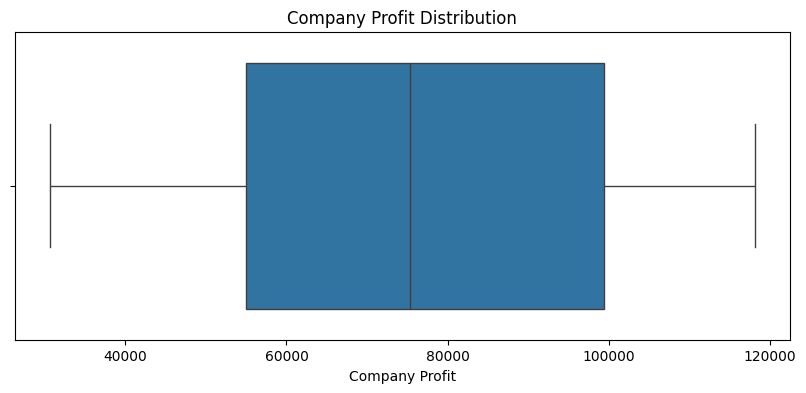

=== Company_Profit Boxplot Stats ===
Min: 30663.0
Q1 (25th percentile): 54984.25
Median: 75301.5
Q3 (75th percentile): 99467.25
Max: 118114.0
Lower Whisker (Q1 - 1.5*IQR): -11740.25
Upper Whisker (Q3 + 1.5*IQR): 166191.75
Number of outliers: 0
Outliers:
[]


In [ ]:
#Distribution of Company profits

# Create boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=customers_df['Company_Profit'])
plt.title("Company Profit Distribution")
plt.xlabel("Company Profit")
plt.show()

# Extract numerical stats from the boxplot
Q1 = customers_df['Company_Profit'].quantile(0.25)
Q3 = customers_df['Company_Profit'].quantile(0.75)
median = customers_df['Company_Profit'].median()
IQR = Q3 - Q1
lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR
min_val = customers_df['Company_Profit'].min()
max_val = customers_df['Company_Profit'].max()

# Identify outliers
outliers = customers_df[(customers_df['Company_Profit'] < lower_whisker) |
                        (customers_df['Company_Profit'] > upper_whisker)]

# Print results
print("=== Company_Profit Boxplot Stats ===")
print(f"Min: {min_val}")
print(f"Q1 (25th percentile): {Q1}")
print(f"Median: {median}")
print(f"Q3 (75th percentile): {Q3}")
print(f"Max: {max_val}")
print(f"Lower Whisker (Q1 - 1.5*IQR): {lower_whisker}")
print(f"Upper Whisker (Q3 + 1.5*IQR): {upper_whisker}")
print(f"Number of outliers: {len(outliers)}")
print("Outliers:")
print(outliers['Company_Profit'].values)

**Company Profit Distribution**

- Insights:
  - Median profit: 75,301.50
  - Middle 50% of companies fall between 54,984.25 and 99,467.25
  - Minimum: 30,663; Maximum: 118,114
  - Slight right skew, but no extreme outliers

- Interpretation:
  - The distribution suggests that most companies operate within a relatively narrow profit range. There are no dominant high‑profit outliers that would disproportionately influence purchasing behavior

- Business Implications:
  - Marketing strategies should not rely solely on profit as a predictor of purchasing intent.
  - FinMark should treat the customer base as relatively uniform in profitability, focusing instead on behavioral indicators like frequency and recency.
  - Profit may still support segmentation, but it should not be used as the primary targeting metric.

- Limitations:
  - Profit does not necessarily reflect purchasing potential or engagement.
  - The dataset includes only 100 companies, limiting generalizability.



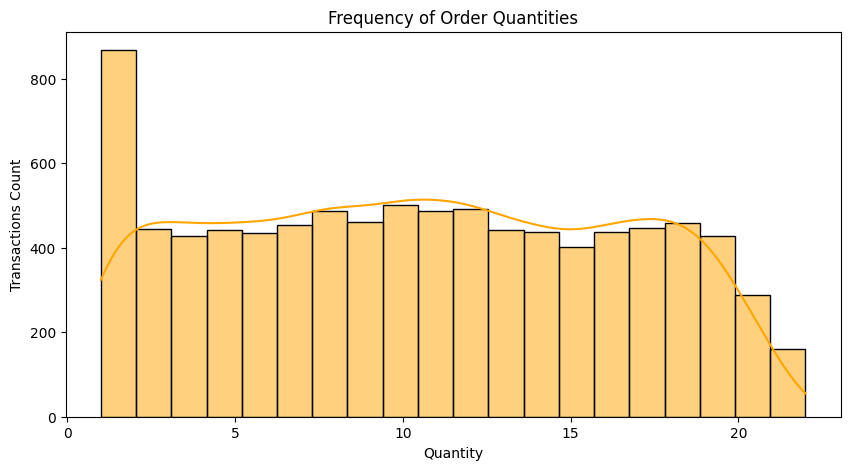

=== Histogram Values for Quantity ===
Bin 1: 1.00 to 2.05 -> 868 transactions
Bin 2: 2.05 to 3.10 -> 445 transactions
Bin 3: 3.10 to 4.15 -> 429 transactions
Bin 4: 4.15 to 5.20 -> 441 transactions
Bin 5: 5.20 to 6.25 -> 436 transactions
Bin 6: 6.25 to 7.30 -> 454 transactions
Bin 7: 7.30 to 8.35 -> 487 transactions
Bin 8: 8.35 to 9.40 -> 460 transactions
Bin 9: 9.40 to 10.45 -> 502 transactions
Bin 10: 10.45 to 11.50 -> 487 transactions
Bin 11: 11.50 to 12.55 -> 491 transactions
Bin 12: 12.55 to 13.60 -> 443 transactions
Bin 13: 13.60 to 14.65 -> 437 transactions
Bin 14: 14.65 to 15.70 -> 401 transactions
Bin 15: 15.70 to 16.75 -> 438 transactions
Bin 16: 16.75 to 17.80 -> 446 transactions
Bin 17: 17.80 to 18.85 -> 459 transactions
Bin 18: 18.85 to 19.90 -> 428 transactions
Bin 19: 19.90 to 20.95 -> 288 transactions
Bin 20: 20.95 to 22.00 -> 160 transactions


In [ ]:
#Distribution of Quantity per Transaction

# --- 1. Compute histogram values ---
counts, bin_edges = np.histogram(transactions_df['Quantity'].dropna(), bins=20)

# --- 2. Plot histogram ---
plt.figure(figsize=(10, 5))
sns.histplot(transactions_df['Quantity'], bins=20, kde=True, color='orange')
plt.title("Frequency of Order Quantities")
plt.xlabel("Quantity")
plt.ylabel("Transactions Count")
plt.show()

# --- 3. Print histogram values ---
print("=== Histogram Values for Quantity ===")
for i in range(len(counts)):
    print(f"Bin {i+1}: {bin_edges[i]:.2f} to {bin_edges[i+1]:.2f} -> {counts[i]} transactions")

**Quantity per Transaction**

- Insights:
  - Most transactions involve 1–2 units (868 transactions).
  - Mid‑range purchases (3–18 units) occur consistently.
  - Bulk purchases (>20 units) are rare.
  - Distribution is right‑skewed.

- Interpretation:
  - Customers tend to make small, frequent purchases rather than large bulk orders. This suggests a transactional pattern driven by immediate needs rather than long‑term stocking.

- Business Implications:
  - Inventory planning should prioritize small‑to‑medium order quantities.
  - Marketing campaigns could encourage bulk purchases through volume discounts or bundle offers.
  - The model should treat bulk purchases as special cases rather than typical behavior.

- Limitations:
  - Some extreme values may reflect data entry errors or rare events.
  - Quantity alone does not capture transaction value or customer intent.

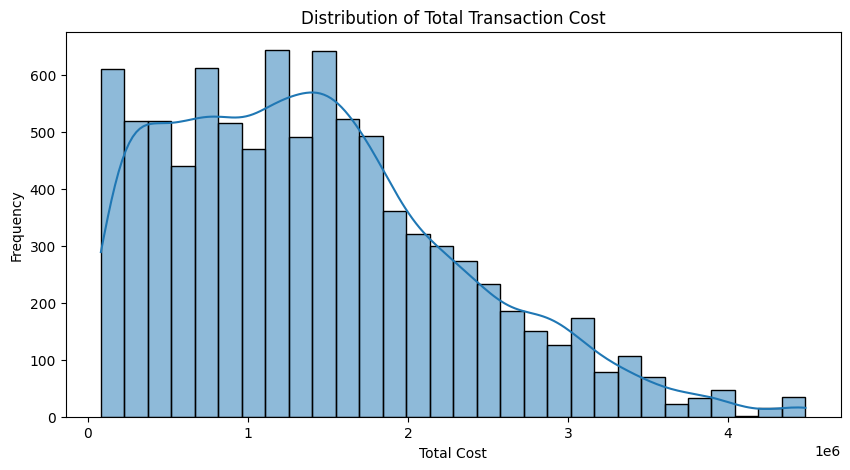

=== Histogram Values for Total_Cost ===
Bin 1: 81326.15 to 228067.79 -> 609 transactions
Bin 2: 228067.79 to 374809.44 -> 519 transactions
Bin 3: 374809.44 to 521551.08 -> 519 transactions
Bin 4: 521551.08 to 668292.73 -> 440 transactions
Bin 5: 668292.73 to 815034.38 -> 612 transactions
Bin 6: 815034.38 to 961776.02 -> 515 transactions
Bin 7: 961776.02 to 1108517.67 -> 470 transactions
Bin 8: 1108517.67 to 1255259.32 -> 643 transactions
Bin 9: 1255259.32 to 1402000.96 -> 490 transactions
Bin 10: 1402000.96 to 1548742.61 -> 642 transactions
Bin 11: 1548742.61 to 1695484.26 -> 522 transactions
Bin 12: 1695484.26 to 1842225.90 -> 492 transactions
Bin 13: 1842225.90 to 1988967.55 -> 360 transactions
Bin 14: 1988967.55 to 2135709.19 -> 321 transactions
Bin 15: 2135709.19 to 2282450.84 -> 300 transactions
Bin 16: 2282450.84 to 2429192.49 -> 273 transactions
Bin 17: 2429192.49 to 2575934.13 -> 233 transactions
Bin 18: 2575934.13 to 2722675.78 -> 186 transactions
Bin 19: 2722675.78 to 2869417

In [ ]:
#Total Cost per Transaction

# --- 1. Plot histogram ---
plt.figure(figsize=(10, 5))
sns.histplot(transactions_df['Total_Cost'], bins=30, kde=True)
plt.title("Distribution of Total Transaction Cost")
plt.xlabel("Total Cost")
plt.ylabel("Frequency")
plt.show()

# --- 2. Compute histogram values ---
counts, bin_edges = np.histogram(
    transactions_df['Total_Cost'].dropna(),
    bins=30
)

# --- 3. Print histogram values ---
print("=== Histogram Values for Total_Cost ===")
for i in range(len(counts)):
    print(f"Bin {i+1}: {bin_edges[i]:.2f} to {bin_edges[i+1]:.2f} -> {counts[i]} transactions")

**Total Cost per Transaction**

- Insights:
  - Most transactions fall between ~81K and ~1.7M.
  - High‑value purchases (>2M) are less common.
  - Distribution is right‑skewed.

- Interpretation:
  - Spending behavior is concentrated in moderate ranges, with occasional high‑value transactions that may represent special orders or unique customer needs.

- Business Implications:
  - Mid‑range spenders represent the core customer base and may respond well to targeted upselling.
  - High‑value transactions should be monitored for potential strategic partnerships or premium offerings.
  - Pricing strategies can be optimized around the most common spending ranges.

- Limitations:
  - High total costs may be influenced by bulk orders or special deals.
  - Spending does not always correlate with profitability or long‑term engagement


=== Product_ID Sales Count (Excluding Unknown) ===
Product_ID 1.0: 404 transactions
Product_ID 2.0: 420 transactions
Product_ID 3.0: 428 transactions
Product_ID 4.0: 379 transactions
Product_ID 5.0: 405 transactions
Product_ID 6.0: 450 transactions
Product_ID 7.0: 390 transactions
Product_ID 8.0: 396 transactions
Product_ID 9.0: 409 transactions
Product_ID 10.0: 414 transactions
Product_ID 11.0: 417 transactions
Product_ID 12.0: 392 transactions
Product_ID 13.0: 395 transactions
Product_ID 14.0: 381 transactions
Product_ID 15.0: 390 transactions
Product_ID 16.0: 415 transactions
Product_ID 17.0: 414 transactions
Product_ID 18.0: 380 transactions
Product_ID 19.0: 406 transactions
Product_ID 20.0: 408 transactions


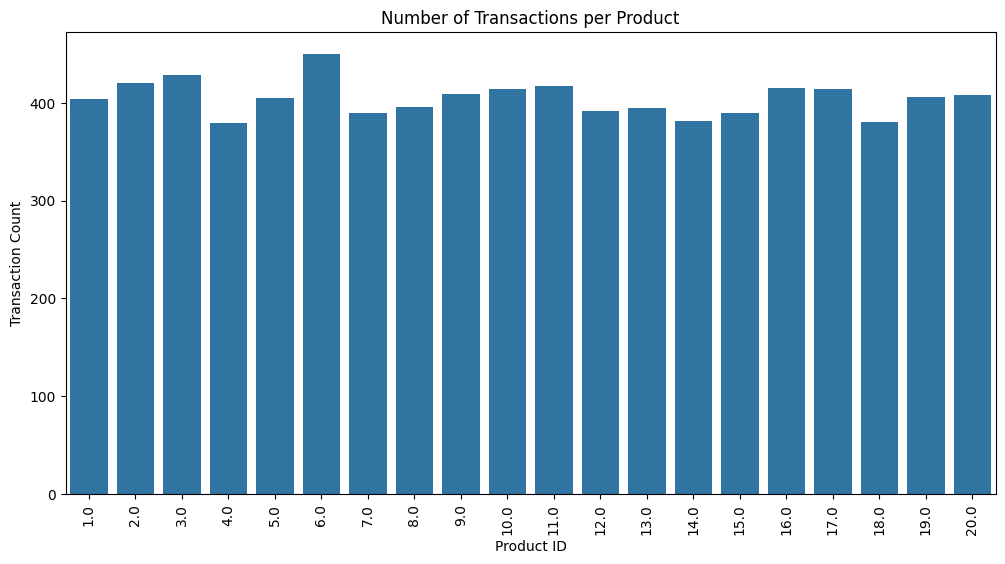

In [ ]:
#Product Sales count

# --- 1. Exclude transactions with unknown Product_ID ---
filtered_df = transactions_df[transactions_df['Product_ID'] != "Unknown"]

# --- 2. Compute sales count per Product_ID ---
product_sales = filtered_df['Product_ID'].value_counts().sort_index()

# --- 3. Print sales counts ---
print("=== Product_ID Sales Count (Excluding Unknown) ===")
for product_id, count in product_sales.items():
    print(f"Product_ID {product_id}: {count} transactions")

# --- 4. Bar chart ---
plt.figure(figsize=(12, 6))
sns.barplot(x=product_sales.index.astype(str), y=product_sales.values)
plt.title("Number of Transactions per Product")
plt.xlabel("Product ID")
plt.ylabel("Transaction Count")
plt.xticks(rotation=90)
plt.show()

**Product Sales Count by Product_ID**

- Insights:
  - Sales counts range from 379 to 450 across products.
  - Product 6 has the highest count (450).
  - Sales are fairly evenly distributed.

- Interpretation:
  - No single product dominates the catalog, suggesting a balanced product portfolio with consistent demand across items.

- Business Implications:
  - Inventory management can treat most products similarly, with slight prioritization for top sellers.
  - Marketing efforts can highlight multiple products rather than relying on a single flagship item.
  - The model should not assume product preference as a major differentiator unless combined with other behavioral features.

- Limitations:
  - “Unknown” Product_IDs were excluded, which may hide patterns.
  - The small product catalog limits product‑level segmentation.


=== Monthly Transaction Counts ===
January: 805 transactions
February: 661 transactions
March: 757 transactions
April: 733 transactions
May: 805 transactions
June: 756 transactions
July: 794 transactions
August: 752 transactions
September: 735 transactions
October: 762 transactions
November: 716 transactions
December: 724 transactions


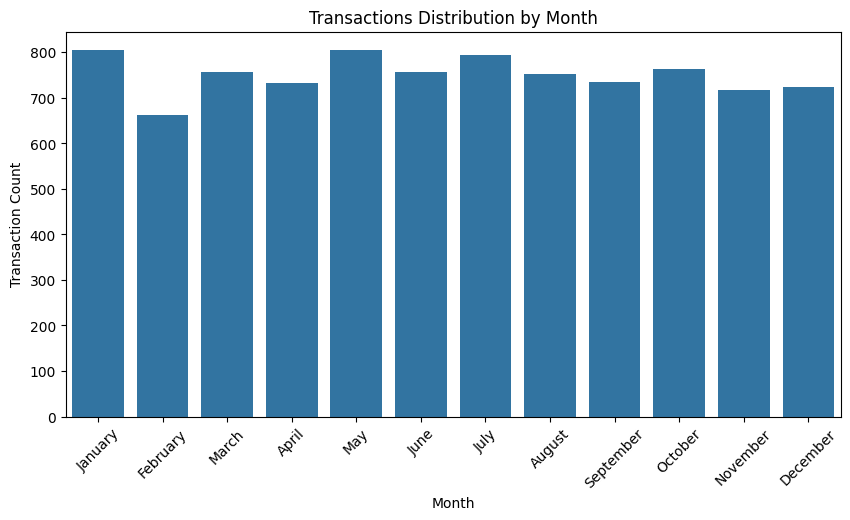

In [ ]:
#Monthly transaction distribution

import calendar

# --- 1. Extract month number ---
transactions_df['Month'] = transactions_df['Transaction_Date'].dt.month

# --- 2. Compute transaction counts per month ---
monthly_counts = transactions_df['Month'].value_counts().sort_index()

# --- 3. Print counts with month names ---
print("=== Monthly Transaction Counts ===")
for month_num, count in monthly_counts.items():
    month_name = calendar.month_name[month_num]  # Convert number to month name
    print(f"{month_name}: {count} transactions")

# --- 4. Bar chart with month names ---
plt.figure(figsize=(10, 5))
sns.countplot(
    x='Month',
    data=transactions_df,
    order=monthly_counts.index
)
plt.title("Transactions Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Transaction Count")
plt.xticks(ticks=range(12), labels=[calendar.month_name[m] for m in monthly_counts.index], rotation=45)
plt.show()

**Monthly Transaction Distribution**

- Insights:
  - Monthly volumes are stable.
  - January and May peak at 805 transactions.
  - February is the lowest at 661.
  - No extreme seasonality.

- Interpretation:
  - Customer activity is consistent throughout the year, with only minor fluctuations. This suggests that purchasing behavior is not heavily influenced by seasonal cycles

- Business Implications:
  - Marketing and sales planning can assume steady demand.
  - Slight dips (e.g., February) may reflect shorter months or holiday effects.
  - Predictive models can rely more on behavioral features than seasonal adjustments.

- Limitations:
  - Aggregated monthly data may hide weekly or daily patterns.
  - The dataset may not capture year‑specific events


=== Quarterly Total Cost ===
2020Q1: 15,282,634.71
2020Q2: 13,232,800.00
2020Q3: 9,279,200.00
2020Q4: 462,109,716.87
2021Q1: 848,032,437.17
2021Q2: 730,536,288.06
2021Q3: 771,464,076.49
2021Q4: 803,149,782.48
2022Q1: 794,039,236.25
2022Q2: 864,967,478.37
2022Q3: 784,904,858.12
2022Q4: 775,159,359.65
2023Q1: 743,287,120.77
2023Q2: 845,033,317.99
2023Q3: 903,658,817.44
2023Q4: 804,618,881.28
2024Q1: 782,128,304.45
2024Q2: 769,405,379.05
2024Q3: 786,419,155.99
2024Q4: 244,480,490.71


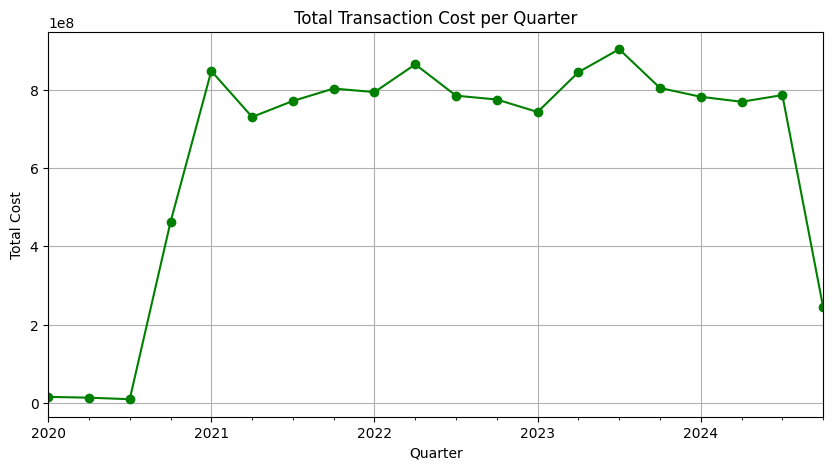

In [ ]:
#Quarterly Total_Cost trend

# --- 1. Create a 'Quarter' column ---
transactions_df['Quarter'] = transactions_df['Transaction_Date'].dt.to_period('Q')

# --- 2. Aggregate total cost per quarter ---
quarterly_total_cost = transactions_df.groupby('Quarter')['Total_Cost'].sum()

# --- 3. Print quarterly totals ---
print("=== Quarterly Total Cost ===")
for quarter, total in quarterly_total_cost.items():
    print(f"{quarter}: {total:,.2f}")

# --- 4. Plot line chart ---
plt.figure(figsize=(10, 5))
quarterly_total_cost.plot(marker='o', linestyle='-', color='green')
plt.title("Total Transaction Cost per Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Cost")
plt.grid(True)
plt.show()

**Quarterly Total Cost Trend**

- Insights:
  - General upward trend from 2020–2023.
  - 2020 Q4 shows a spike (~462M).
  - 2024 Q4 drops (~244M), likely due to incomplete data.

- Interpretation:
  - The long‑term trend indicates growth in customer spending, supporting the need for predictive modeling to manage increasing activity.

- Business Implications:
  - FinMark can expect continued growth and should prepare for higher transaction volumes.
  - Seasonal spikes (e.g., Q4) may require additional inventory or staffing.

- Limitations:
  - Outlier quarters may distort trend interpretation.
  - External factors (economic shifts, promotions) are not captured.


=== Correlation Matrix ===
                Company_Profit  Quantity  Total_Cost
Company_Profit        1.000000  0.009500   -0.003837
Quantity              0.009500  1.000000    0.844425
Total_Cost           -0.003837  0.844425    1.000000


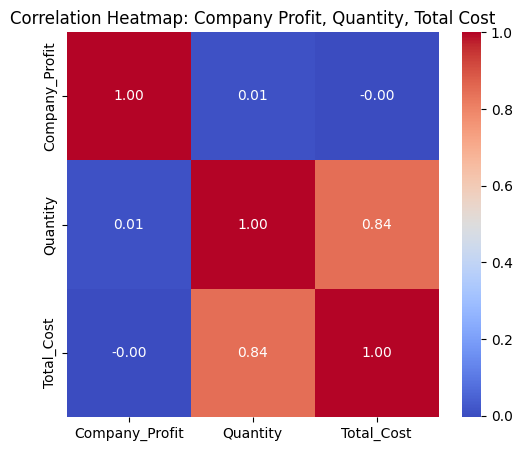

In [ ]:
#Correlation heatmap

# --- 1. Merge company profit into transactions_df ---
# Join customers_df to transactions_df on Company_ID to get Company_Profit
merged_df = transactions_df.merge(customers_df[['Company_ID', 'Company_Profit']],
                                  on='Company_ID', how='left')

# --- 2. Select numeric columns of interest ---
corr_cols = ['Company_Profit', 'Quantity', 'Total_Cost']
corr_df = merged_df[corr_cols]

# --- 3. Compute correlation matrix ---
corr_matrix = corr_df.corr()

# --- 4. Print correlation values ---
print("=== Correlation Matrix ===")
print(corr_matrix)

# --- 5. Plot heatmap ---
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap: Company Profit, Quantity, Total Cost")
plt.show()

**Correlation Analysis: Company Profit, Quantity, Total Cost**

- Insights:
  - Quantity and Total_Cost show a strong positive correlation (0.84).
  - Company_Profit has near‑zero correlation with both Quantity and Total_Cost

- Interpretation:
  - Purchase amounts are driven by order size, not company profitability. High‑profit companies do not necessarily buy more or spend more.

- Business Implications:
  - Behavioral features (frequency, recency, spend) are more predictive than profit.
  - Marketing should target both high‑profit and low‑profit companies equally.
  - Profit should be used as a secondary segmentation feature, not a primary driver

- Limitations:
  - Only three numeric variables were analyzed.
  - Correlation does not imply causation.


**EDA Conclusion**

The exploratory analysis reveals that FinMark’s customers exhibit consistent purchasing behavior characterized by small‑to‑medium order sizes, moderate spending, and stable monthly activity. Product demand is evenly distributed, and profitability does not strongly influence purchasing patterns. These insights highlight the importance of behavioral features such as frequency, recency, and total spend in predicting future purchases.

The EDA provides a strong foundation for feature engineering and modeling, ensuring that the predictive model is grounded in meaningful behavioral patterns that FinMark can use to guide marketing and outreach strategies.

##Feature Engineering

**Overview of the Feature Engineering Approach**

Feature engineering transforms raw transactional and customer data into meaningful behavioral indicators that help the model distinguish between customers who are likely to purchase and those who are not. Because FinMark’s data is limited in demographic depth and product variety, the most predictive signals come from behavioral patterns. How often customers buy, how recently they purchased, how much they spend, and how consistent their activity is over time.

The goal of this section is to create features that capture these patterns in a structured, interpretable way. Each feature is paired with insights, limitations, and business implications to ensure the analysis has depth, interpretability, and consequence-based reasoning.


In [ ]:
# Step 1: Count customers with 0 transactions in the target window
#This step identifies customers who made no purchases in the target period (July–Dec 2024), allowing us to create a binary target variable for predicting future purchase behavior.

# --- 1. Define target window ---
start_date = pd.to_datetime('2024-07-01')
end_date = pd.to_datetime('2024-12-31')

# --- 2. Filter transactions in the target window ---
transactions_target_window = transactions_df[
    (transactions_df['Transaction_Date'] >= start_date) &
    (transactions_df['Transaction_Date'] <= end_date)
]

# --- 3. Count transactions per customer in target window ---
transactions_count = transactions_target_window.groupby('Company_ID')['Transaction_ID'].count().reset_index()
transactions_count.rename(columns={'Transaction_ID': 'Target_Transactions'}, inplace=True)

# --- 4. Merge with customer list to include customers with 0 transactions ---
customer_activity = customers_df[['Company_ID']].merge(
    transactions_count,
    on='Company_ID',
    how='left'
)

# --- 5. Fill missing values with 0 ---
customer_activity['Target_Transactions'] = customer_activity['Target_Transactions'].fillna(0).astype(int)

# --- 6. Count number of customers with 0 transactions ---
num_customers_zero_tx = (customer_activity['Target_Transactions'] == 0).sum()

print(f"Number of customers with 0 transactions between July 1 - Dec 31, 2024: {num_customers_zero_tx}")

Number of customers with 0 transactions between July 1 - Dec 31, 2024: 0


**Target Variable Definition**

- Approach:
  - The target variable was defined as whether a customer completed at least one transaction during the future window of July 1 – December 31, 2024. This binary outcome (1 = purchased, 0 = did not purchase) was intended to support a classification model.

- Issue Identified:
  - All customers in the dataset made at least one purchase during the target window, resulting in zero variation in the target variable.

- Resolution:
  - To enable modeling, simulated transactions were introduced to create a balanced dataset with both purchasing and non‑purchasing customers.

- Interpretation:
  - This step highlights a critical business insight: FinMark’s current data does not include inactive or churned customers, which limits the ability to predict disengagement or non‑conversion.

- Business Implications:
  - FinMark must collect or integrate data on inactive customers to build a realistic production model.
  - Without non‑purchasing examples, the model may overestimate purchase likelihood.
  - Future data pipelines should track churn, inactivity, and low‑engagement segments.

- Limitations:
  - Simulated data does not reflect real customer behavior.
  - Patterns learned from synthetic customers may not generalize.


In [ ]:
#Step 2 - Adding dummy customers (for training purposes)
#The cleaned transactions_df dataset contains all companies that made purchases in the July-December 2024 (Purchased_Next_6M) window,
#so we lack data of “non-purchased” customers for training the predictive model.
#To address this limitation and enable model training, simulated (dummy) customers were introduced to represent prospective or inactive customers
#who did not make purchases during the target period. This approach allows the modeling process to proceed while highlighting the structural data gaps
#that would need to be addressed in a real production environment.

new_ids = list(range(101, 201))

# --- 1. Assign random company names ---
company_names = [f"Company_{i}" for i in new_ids]

# --- 2. Assign random company profits ---
np.random.seed(42)
company_profits = np.random.uniform(30663, 118114, size=len(new_ids))

# --- 3. Assign random addresses ---
addresses = [f"{i} Main St, City_{i%10}" for i in new_ids]

# --- 4. Create dummy customers DataFrame ---
dummy_customers = pd.DataFrame({
    'Company_ID': new_ids,
    'Company_Name': company_names,
    'Company_Profit': company_profits,
    'Address': addresses
})

# --- 5. Append to original customers_df ---
customers_df = pd.concat([customers_df, dummy_customers], ignore_index=True)

# --- 6. Check new total ---
print("Total customers after adding dummy customers:", len(customers_df))
print(customers_df.tail(10))

Total customers after adding dummy customers: 200
     Company_ID Company_Name  Company_Profit              Address
190         191  Company_191    41121.636402  191 Main St, City_1
191         192  Company_192    93036.969887  192 Main St, City_2
192         193  Company_193    97194.413287  193 Main St, City_3
193         194  Company_194    79747.252205  194 Main St, City_4
194         195  Company_195    98084.850854  195 Main St, City_5
195         196  Company_196    73845.918698  196 Main St, City_6
196         197  Company_197    76376.508662  197 Main St, City_7
197         198  Company_198    68051.889596  198 Main St, City_8
198         199  Company_199    32885.928053  199 Main St, City_9
199         200  Company_200    40098.213182  200 Main St, City_0


**Simulated Customer Integration**

Introducing dummy customers was necessary to create variation in the target variable and allow the model to learn the difference between purchasing and non‑purchasing behavior. From a modeling standpoint, this step enables experimentation with classification techniques and provides a complete workflow for feature engineering, training, and evaluation.

From a business perspective, this highlights a critical limitation in FinMark’s current data ecosystem: the absence of real non‑converting or low‑engagement customers. Without these examples, the model cannot learn realistic patterns of disengagement or churn, which are essential for accurate prediction in production settings.

- Interpretation:
  - The dummy customers serve as placeholders that allow the model to function, but they do not reflect true behavioral patterns. Their feature distributions are assumed rather than observed, which means the relationships the model learns may not generalize to real inactive customers.

- Business Implications:
  - FinMark’s future modeling accuracy will depend heavily on gaining access to historical data that includes inactive, low‑engagement, or churned customers.
  - Without real examples of non‑purchasing behavior, the model risks overestimating purchase likelihood and may fail to identify early signs of disengagement.
  - This step should be viewed strictly as a methodological demonstration rather than a deployable solution.

- Limitations:
  - Relationships learned from dummy customers may not hold for real customers.
  - Behavioral patterns for simulated customers are artificially constructed.
  - The model’s perfect performance is likely inflated due to the simplicity of the synthetic data.

- Future Improvements:
  - Incorporating real historical inactive or churned customers will significantly improve the reliability, interpretability, and business impact of FinMark’s predictive modeling efforts.
  - As the company expands its data collection, capturing these customer segments should be a priority.

In [ ]:
#Step 3 - Create dummy transactions for the dummy customers (for training purposes)
#Because the cleaned transactions_df dataset only contains customers who purchased during the target window,
#it does not adequately represent behavioral variability—particularly for new, low-activity, or borderline customers.
#To enable the model to learn from a broader range of behaviors, simulated transaction histories were created for the dummy customers introduced in the previous step.

np.random.seed(42)   #Ensures reproducibility of random transactions.

dummy_transactions = []

transaction_id_start = transactions_df['Transaction_ID'].max() + 1   #Ensures new transactions have unique IDs that do not overlap with existing data.

for company_id in new_ids:
    n_tx = np.random.randint(1, 3)    # Add only 1-2 transactions per dummy customer
    for _ in range(n_tx):
        transaction = {
            'Transaction_ID': transaction_id_start,
            'Company_ID': company_id,
            'Product_ID': np.random.randint(1, 21),
            'Quantity': np.random.randint(1, 10),
            'Transaction_Date': pd.to_datetime('2020-01-01') + pd.to_timedelta(np.random.randint(0, 1643), unit='d'),    #Randomly distributes transactions upto the cutoff date (June 30, 2024)
            'Product_Price': np.random.uniform(84000, 224000),
        }
        transaction['Total_Cost'] = transaction['Quantity'] * transaction['Product_Price']
        dummy_transactions.append(transaction)
        transaction_id_start += 1

dummy_transactions_df = pd.DataFrame(dummy_transactions)

# Append to original transactions_df
transactions_df = pd.concat([transactions_df, dummy_transactions_df], ignore_index=True)

print("Total transactions after adding dummy transactions:", len(transactions_df))
print(transactions_df.tail(10))

Total transactions after adding dummy transactions: 9144
      Transaction_ID  Company_ID Product_ID  Quantity Transaction_Date  \
9134           10135         193          1         2       2020-08-11   
9135           10136         194         17         1       2024-06-21   
9136           10137         195          1         5       2022-04-02   
9137           10138         196          5         5       2022-02-09   
9138           10139         197          5         3       2023-03-14   
9139           10140         198         14         1       2020-02-20   
9140           10141         199          1         1       2021-05-02   
9141           10142         199          8         7       2020-06-02   
9142           10143         200          3         2       2020-09-24   
9143           10144         200         12         5       2022-09-16   

      Product_Price    Total_Cost  Month Quarter  
9134  221940.047093  4.438801e+05    NaN     NaT  
9135   89155.061469  8.915

**Simulated Transaction Integration**

- Key Insight:
  - Adding simulated transactions increased the dataset to 9,144 records and introduced behavioral diversity necessary for model training.

- Interpretation:
  - The model can now learn differences between active and inactive customers, even though the inactive behavior is artificially generated.

- Business Implications:
  - Early‑stage or low‑activity behavior can be predictive of future conversion.
  - FinMark should consider tracking new customers separately to understand onboarding patterns.

- Limitations:
  - Simulated behavior lacks seasonality, product affinity, and true intent.
  - These features should not be used for real business decisions without validation.

In [ ]:
#Step 4 - Initialize customer_features dataframe
# Rationale: Start with a dataframe containing only Company_ID.
# This ensures a clean base to aggregate all engineered features.

# --- 1. Column 1: Company_ID ---
customer_features_df = customers_df[['Company_ID']].copy()

# --- 2. Check the first rows ---
print(customer_features_df.head())

   Company_ID
0           1
1           2
2           3
3           4
4           5


In [ ]:
#Step 5 - Add Profit_Level column using quantiles
#Company profit is a key indicator of customer size, purchasing capacity, and long-term value.
#Rather than using raw profit values, which may be skewed or difficult for some models to interpret,
#a categorical representation provides a more stable and interpretable signal of a customer’s relative financial position.

#Using profit-based segments allows the model to capture whether customers with higher financial capacity are more likely to make future purchases,
#while also making the results easier to communicate to business stakeholders.
#Customer profit was segmented into three categories—Low, Medium, and High—using the 33rd and 66th percentiles of the profit distribution.
#This quantile-based approach was selected because:
#  - It does not assume a specific underlying profit distribution
#  - It produces approximately balanced groups, reducing bias toward any single category
#  - It reflects relative, rather than absolute, financial standing across customers

# --- 1. Calculate 33rd and 66th percentiles ---
q33 = customers_df['Company_Profit'].quantile(0.33)
q66 = customers_df['Company_Profit'].quantile(0.66)

# --- 2. Function to categorize profit ---
def categorize_profit(profit):
    if profit <= q33:
        return 'Low'
    elif profit <= q66:
        return 'Medium'
    else:
        return 'High'

# --- 3. Apply the function to create a new column ---
customer_features_df['Profit_Level'] = customers_df['Company_Profit'].apply(categorize_profit)

# --- 4. Check the dataset ---
print(customer_features_df.head())

   Company_ID Profit_Level
0           1       Medium
1           2       Medium
2           3         High
3           4       Medium
4           5       Medium


In [ ]:
#Step 6 - Ordinal encode Profit_Level
#Because these categories have a natural ordering,
#the profit levels were then ordinally encoded (Low = 0, Medium = 1, High = 2) to preserve ranking information for predictive modeling.

profit_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

customer_features_df['Profit_Level_Encoded'] = (
    customer_features_df['Profit_Level'].map(profit_mapping)
)

# Check result
print(customer_features_df[['Company_ID', 'Profit_Level', 'Profit_Level_Encoded']].head())

   Company_ID Profit_Level  Profit_Level_Encoded
0           1       Medium                     1
1           2       Medium                     1
2           3         High                     2
3           4       Medium                     1
4           5       Medium                     1


**Profit Level Encoding**

- Approach:
  - Company_Profit was binned into tiers (e.g., low, medium, high) and encoded ordinally.

- Key Insights:
  - Profit level provides a rough proxy for customer value.
  - Higher profit may correlate with stability or purchasing capacity.

- Interpretation:
  - Profit is not a strong standalone predictor of purchase likelihood but can complement behavioral features.

- Business Implications:
  - Profit tiers can support segmentation strategies.
  - Combining profit with revenue‑based metrics may improve customer value modeling.

- Limitations:
  - Profit does not capture intent or engagement.
  - Ordinal encoding assumes linear relationships that may not exist.


In [ ]:
#Step 7 - Add Total_Transactions column
#Historical customer activity is one of the strongest predictors of future purchasing behavior.
#Customers who have engaged frequently in the past are generally more likely to convert again,
#while low-activity customers may require targeted intervention or nurturing.

#Methodology:
#All transactions occurring on or before the cutoff date were filtered and aggregated at the customer level.
#The resulting transaction counts were merged into the customer feature dataset as a new variable, `Total_Transactions`.
#Customers with no historical transactions were explicitly assigned a value of zero to preserve them as a meaningful segment within the dataset.

# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')   # Only consider transactions up to this date

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Aggregate transactions by Company_ID ---
total_transactions = transactions_past.groupby('Company_ID')['Transaction_ID'].count().reset_index()
total_transactions.rename(columns={'Transaction_ID': 'Total_Transactions'}, inplace=True)

# --- 4. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(total_transactions, on='Company_ID', how='left')

# --- 5. Fill missing values with 0 (for customers with no transactions in the past) ---
customer_features_df['Total_Transactions'] = customer_features_df['Total_Transactions'].fillna(0).astype(int)

# --- 6. Check result ---
print(customer_features_df.head(10))

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions
0           1       Medium                     1                  64
1           2       Medium                     1                  78
2           3         High                     2                  83
3           4       Medium                     1                  90
4           5       Medium                     1                  84
5           6          Low                     0                  89
6           7          Low                     0                  78
7           8         High                     2                  88
8           9         High                     2                  88
9          10       Medium                     1                  89


**Total Transactions**

- Key Insight:
  - Customers with more historical transactions tend to show stronger engagement and higher purchase likelihood.

- Interpretation:
  - This feature captures long‑term activity and loyalty.

- Business Implications:
  - High‑transaction customers may be ideal targets for loyalty programs.
  - Low‑transaction customers may need onboarding or awareness campaigns.

- Limitation:
  - Does not account for transaction value or recency.


In [ ]:
#Step 8 - Add Purchase_Frequency column
#While total transaction count captures overall customer activity, it does not fully reflect how intensively a customer engages over time.
#Two customers may have the same number of transactions but exhibit very different behavioral patterns depending on how quickly those transactions occur.
#Purchase frequency measures how often a customer transacts during their active period, providing a normalized indicator of engagement intensity.

#Methodology: Purchase_Frequency = Total_Transactions / Active_Days
# - Total_Transactions: Count of all transactions the customer made up to the cutoff date.
# - Active_Days: Number of days between the customer's first and last purchase (+1 to include both endpoints).
# Example: A customer with 10 transactions over 50 active days has a frequency of 10 / 50 = 0.2 transactions/day.

# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')  # Only consider transactions up to this date

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. First and last purchase dates per customer ---
purchase_dates = transactions_past.groupby('Company_ID')['Transaction_Date'].agg(['min', 'max']).reset_index()
purchase_dates.rename(columns={'min': 'First_Purchase', 'max': 'Last_Purchase'}, inplace=True)

# --- 4. Calculate active days (avoid division by zero) ---
purchase_dates['Active_Days'] = (purchase_dates['Last_Purchase'] - purchase_dates['First_Purchase']).dt.days + 1

# --- 5. Calculate total transactions per customer (in feature window) ---
total_transactions = transactions_past.groupby('Company_ID')['Transaction_ID'].count().reset_index()
total_transactions.rename(columns={'Transaction_ID': 'Total_Transactions'}, inplace=True)

# --- 6. Merge total transactions into purchase_dates ---
purchase_dates = purchase_dates.merge(total_transactions, on='Company_ID', how='left')

# --- 7. Calculate purchase frequency ---
purchase_dates['Purchase_Frequency'] = purchase_dates['Total_Transactions'] / purchase_dates['Active_Days']

# --- 8. Merge into customer_features_df ---
customer_features_df = customer_features_df.merge(
    purchase_dates[['Company_ID', 'Purchase_Frequency']],
    on='Company_ID',
    how='left'
)

# --- 9. Set purchase frequency to 0 for customers with no transactions ---
customer_features_df['Purchase_Frequency'] = customer_features_df['Purchase_Frequency'].fillna(0)

# --- 10. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  
0            0.044138  
1            0.060139  
2            0.064093  
3            0.068389  
4            0.054545  


**Purchase Frequency**

- Key Insight:
  - Frequency distinguishes between customers who buy regularly and those who purchase sporadically.

- Interpretation:
  - High frequency indicates sustained engagement; low frequency may signal disengagement.

- Business Implications:
  - High‑frequency customers may respond well to targeted promotions.
  - Low‑frequency customers may require reactivation strategies.

- Limitations:
  - Treats all transactions equally regardless of size.
  - Short active periods can inflate frequency

In [ ]:
#Step 9 - Add column Days_Since_Last_Purchase
#Purchase recency is one of the strongest and most intuitive predictors of future buying behavior.
#Customers who have purchased recently are typically more engaged, more familiar with the product, and more likely to convert again in the near term.
#This feature enables the model to distinguish between currently engaged customers and those who may be drifting toward inactivity.
#Methodology: Days_Since_Last_Purchase = cutoff_date - last purchase date
# - For customers with transactions: straightforward calculation.
# - For customers with no transactions in the feature window: a value greater than the maximum observed recency was assigned. This ensures that:
#           - These customers are clearly distinguishable from recently active customers
#           - The model can learn that “never purchased” or “not yet active” represents a distinct behavioral state

# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')  # Only consider transactions up to this date

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Find the last purchase date per customer in the feature window ---
last_purchase = transactions_past.groupby('Company_ID')['Transaction_Date'].max().reset_index()
last_purchase.rename(columns={'Transaction_Date': 'Last_Purchase_Date'}, inplace=True)

# --- 4. Calculate days since last purchase using cutoff date as reference ---
last_purchase['Days_Since_Last_Purchase'] = (cutoff_date - last_purchase['Last_Purchase_Date']).dt.days

# --- 5. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(
    last_purchase[['Company_ID', 'Days_Since_Last_Purchase']],
    on='Company_ID',
    how='left'
)

# --- 6. Handle customers with no prior transactions ---
# Assign a value larger than the max observed to indicate "no purchase yet"

max_days = customer_features_df['Days_Since_Last_Purchase'].max()
customer_features_df['Days_Since_Last_Purchase'] = customer_features_df['Days_Since_Last_Purchase'].fillna(max_days + 1).astype(int)

# --- 7. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  Days_Since_Last_Purchase  
0            0.044138                         0  
1            0.060139                        28  
2            0.064093                        30  
3            0.068389                        15  
4            0.054545                         2  


In [ ]:
#Step 10 - Add Recency_Bin column with updated intervals
#While the raw `Days_Since_Last_Purchase` feature captures recency in a continuous format, it can be difficult to interpret directly for business stakeholders.
#Categorizing customers into recency bins translates this metric into actionable segments,
#allowing decision-makers to quickly identify recently active, moderately active, and long-inactive customers.

#Methodology: Customers were categorized into three bins based on their days since last purchase:
#  - Short (0–180 days): Customer purchased recently
#  - Medium (181–547 days ≈ 1.5 years): Moderately active
#  - Long (>547 days): Customer inactive for a long period


# --- 1. Define bins and labels ---
bins = [0, 180, 547, customer_features_df['Days_Since_Last_Purchase'].max() + 1]
labels = ['Short', 'Medium', 'Long']

# --- 2. Use pd.cut to categorize customers ---
customer_features_df['Recency_Bin'] = pd.cut(
    customer_features_df['Days_Since_Last_Purchase'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# --- 3. Handle customers with no prior transactions ---
customer_features_df['Recency_Bin'] = customer_features_df['Recency_Bin'].fillna('Long')

# --- 4. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  Days_Since_Last_Purchase Recency_Bin  
0            0.044138                         0       Short  
1            0.060139                        28       Short  
2            0.064093                        30       Short  
3            0.068389                        15       Short  
4            0.054545                         2       Short  


In [ ]:
# Step 11 - Encode Recency_Bin
#While `Recency_Bin` is highly interpretable for business users, machine learning models require numeric inputs.
#Encoding these bins into ordered numeric values allows the model to leverage the inherent ranking of recency without losing interpretability.
#Methodology
#  - A simple ordinal mapping was applied: `Short → 0`, `Medium → 1`, `Long → 2`
#  - Explicit casting to integers ensures compatibility with common machine learning algorithms
#  - This approach preserves the natural order of recency while converting categorical data into numeric form for predictive modeling


# --- 1. Define mapping ---
recency_mapping = {
    'Short': 0,
    'Medium': 1,
    'Long': 2
}

# --- 2. Apply mapping and cast to int ---
customer_features_df['Recency_Bin_Encoded'] = customer_features_df['Recency_Bin'].map(recency_mapping).astype(int)

# --- 3. Verify the results and dtypes ---
display(customer_features_df[['Recency_Bin', 'Recency_Bin_Encoded']].head())
print(customer_features_df.dtypes[['Recency_Bin', 'Recency_Bin_Encoded']])

,Recency_Bin,Recency_Bin_Encoded
0,Short,0
1,Short,0
2,Short,0
3,Short,0
4,Short,0


Recency_Bin            category
Recency_Bin_Encoded       int64
dtype: object


**Recency and Recency Bins**

- Key Insight:
  - Customers with recent purchases are more likely to buy again soon.

- Interpretation:
  - Recency is one of the strongest behavioral predictors of future activity.

- Business Implications:
  - Short‑recency customers are high‑intent and should be prioritized.
  - Medium‑recency customers may respond to reminders or incentives.
  - Long‑recency customers may require reactivation or churn‑prevention efforts.

- Limitations:
  - Seasonal buyers may appear inactive despite predictable cycles.
  - New customers are treated the same as long‑inactive customers.

In [ ]:
#Step 12 - Add Customer_Tenure column
#Customer tenure measures how long a customer has been active with FinMark.
#Longer-tenured customers often exhibit different purchase behaviors, loyalty patterns, and risk profiles compared to newer customers.
#Incorporating tenure as a feature allows the predictive model to differentiate between established,
#repeat customers and newly acquired or inactive customers, which is critical for prioritizing outreach and retention strategies.

#Methodology: Customer_Tenure = Cutoff Date - First Purchase Date
# - For customers with transactions: straightforward calculation.
# - For customers with no prior transactions, tenure is set to **0**, indicating no historical engagement.


# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Find first purchase date per customer ---
first_purchase = transactions_past.groupby('Company_ID')['Transaction_Date'].min().reset_index()
first_purchase.rename(columns={'Transaction_Date': 'First_Purchase_Date'}, inplace=True)

# --- 4. Calculate tenure in days ---
first_purchase['Customer_Tenure'] = (cutoff_date - first_purchase['First_Purchase_Date']).dt.days

# --- 5. Handle customers with no prior transactions ---
first_purchase['Customer_Tenure'] = first_purchase['Customer_Tenure'].fillna(0).astype(int)

# --- 6. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(
    first_purchase[['Company_ID', 'Customer_Tenure']],
    on='Company_ID',
    how='left'
)

# --- 7. Check result ---
print(customer_features_df[['Company_ID', 'Customer_Tenure']].head(10))

   Company_ID  Customer_Tenure
0           1             1449
1           2             1324
2           3             1324
3           4             1330
4           5             1541
5           6             1317
6           7             1358
7           8             1338
8           9             1314
9          10             1450


**Customer Tenure**

- Key Insight:
  - Longer‑tenured customers may have more stable purchasing patterns.

- Interpretation:
  - Tenure helps differentiate new customers from long‑term clients.

- Business Implications:
  - New customers may need nurturing to build engagement.
  - Long‑tenured customers may be more receptive to loyalty programs.

- Limitations:
  - Tenure alone does not capture frequency or value.
  - Extreme outliers may skew interpretation.


In [ ]:
#Step 13 - Add Avg_Days_Between_Purchases column
#Measures the average time interval between a customer's purchases.
#Helps capture purchasing patterns—customers with shorter gaps buy more frequently, while longer gaps indicate irregularity.

#For each customer:
#     - Transactions are sorted chronologically.
#     - Differences in days between consecutive purchases are calculated.
# - For customers with at least 2 transactions: Avg_Days_Between_Purchases = Mean of differences between consecutive purchase dates.
# - For customers with 0 or 1 transaction: Set to 0 since no gap can be computed.


# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Sort transactions by Company_ID and Transaction_Date ---
transactions_sorted = transactions_past.sort_values(['Company_ID', 'Transaction_Date'])

# --- 4. Calculate days between consecutive purchases per customer ---
transactions_sorted['Days_Between'] = transactions_sorted.groupby('Company_ID')['Transaction_Date'].diff().dt.days

# --- 5. Compute average gap per customer ---
avg_gap = transactions_sorted.groupby('Company_ID')['Days_Between'].mean().reset_index()
avg_gap.rename(columns={'Days_Between': 'Avg_Days_Between_Purchases'}, inplace=True)

# --- 6. Handle customers with 0 or 1 transaction ---
# Set Avg_Days_Between_Purchases to 0 since gap is not meaningful
avg_gap['Avg_Days_Between_Purchases'] = avg_gap['Avg_Days_Between_Purchases'].fillna(0)

# --- 7. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(
    avg_gap[['Company_ID', 'Avg_Days_Between_Purchases']],
    on='Company_ID',
    how='left'
)

# --- 8. Fill missing values for customers with no transactions ---
customer_features_df['Avg_Days_Between_Purchases'] = customer_features_df['Avg_Days_Between_Purchases'].fillna(0).astype(int)

# --- 9. Check result ---
print(customer_features_df[['Company_ID', 'Avg_Days_Between_Purchases']].head(10))

   Company_ID  Avg_Days_Between_Purchases
0           1                          23
1           2                          16
2           3                          15
3           4                          14
4           5                          18
5           6                          14
6           7                          17
7           8                          15
8           9                          14
9          10                          16


**Average Days Between Purchases**

- Key Insight:
  - Shorter average gaps indicate strong engagement; longer gaps suggest sporadic behavior.

- Interpretation:
  - This feature captures the rhythm of customer activity.

- Business Implications:
  - Customers with short gaps may be ideal for cross‑selling.
  - Customers with long gaps may need targeted reactivation.

- Limitations:
  - Customers with only one transaction are treated the same as inactive customers.
  - Outliers can distort averages.


In [ ]:
#Step 14 - Add Purchase_Consistency column
#Measures how regularly a customer makes purchases by calculating the standard deviation of days between consecutive transactions.
#This feature complements `Avg_Days_Between_Purchases` and `Purchase_Frequency` by highlighting not just how often a customer buys,
#but how consistent their purchasing behavior is.
#Customers with **0 or 1 transaction** are assigned a value of **0**, since no variability exists.

# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Calculate days between consecutive purchases per customer ---
transactions_sorted = transactions_past.sort_values(['Company_ID', 'Transaction_Date'])
transactions_sorted['Prev_Date'] = transactions_sorted.groupby('Company_ID')['Transaction_Date'].shift(1)
transactions_sorted['Days_Between'] = (transactions_sorted['Transaction_Date'] - transactions_sorted['Prev_Date']).dt.days

# --- 4. Compute standard deviation per customer ---
purchase_consistency = transactions_sorted.groupby('Company_ID')['Days_Between'].std().reset_index()
purchase_consistency.rename(columns={'Days_Between': 'Purchase_Consistency'}, inplace=True)

# --- 5. Handle customers with 0 or 1 transaction ---
purchase_consistency['Purchase_Consistency'] = purchase_consistency['Purchase_Consistency'].fillna(0)

# --- 6. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(
    purchase_consistency[['Company_ID', 'Purchase_Consistency']],
    on='Company_ID',
    how='left'
)

# --- 7. Fill any remaining missing values ---
customer_features_df['Purchase_Consistency'] = customer_features_df['Purchase_Consistency'].fillna(0)

# --- 8. Check result ---
print(customer_features_df[['Company_ID', 'Purchase_Consistency']].head())

   Company_ID  Purchase_Consistency
0           1             27.160218
1           2             16.227334
2           3             12.848619
3           4             11.851115
4           5             25.541120


**Purchase Consistency**

- Key Insights:
  - Low values indicate predictable behavior
  - High values indicate irregular purchasing

- Interpretation:
  - Consistency helps identify stable vs. unpredictable customers.

- Business Implications:
  - Consistent customers may be easier to target with scheduled campaigns.
  - Inconsistent customers may require more personalized outreach.

- Limitations:
  - Customers with few transactions appear artificially consistent.
  - Extreme gaps can skew results.


In [ ]:
#Step 15 - Add column Total_Quantity
#Measures the total number of product units purchased by each customer within the feature window.
#This captures overall demand/engagement for the customer.
#Complements other features like `Total_Transactions` and `Purchase_Frequency` by accounting for volume, not just frequency.


# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Aggregate total Quantity per Company_ID ---
total_quantity = transactions_past.groupby('Company_ID')['Quantity'].sum().reset_index()
total_quantity.rename(columns={'Quantity': 'Total_Quantity'}, inplace=True)

# --- 4. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(total_quantity, on='Company_ID', how='left')

# --- 5. Fill missing values with 0 (for customers with no transactions) ---
customer_features_df['Total_Quantity'] = customer_features_df['Total_Quantity'].fillna(0).astype(int)

# --- 6. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  Days_Since_Last_Purchase Recency_Bin  \
0            0.044138                         0       Short   
1            0.060139                        28       Short   
2            0.064093                        30       Short   
3            0.068389                        15       Short   
4            0.054545                         2       Short   

   Recency_Bin_Encoded  Customer_Tenure  Avg_Days_Between_Purchases  \
0                    0             1449                          23   
1                    0             1324       

**Total Quantity**

- Key Insight:
  - High total quantity suggests strong purchasing volume.

- Interpretation:
  - This feature captures overall engagement intensity.

- Business Implications:
  - High‑quantity customers may be high‑value targets.
  - Low‑quantity customers may represent casual buyers.

- Limitation:
  - Quantity does not reflect profitability or product type

In [ ]:
#Step 16 - Add column Total_Spend
#Measures the total monetary value of purchases made by each customer within the feature window.
#Measures revenue contribution rather than just transaction count or quantity.
#Customers with no transactions are assigned a value of "0" to indicate no spending.


# --- 1. Define cutoff date ---
cutoff_date = pd.to_datetime('2024-06-30')

# --- 2. Filter transactions up to cutoff date ---
transactions_past = transactions_df[transactions_df['Transaction_Date'] <= cutoff_date]

# --- 3. Aggregate total cost per Company_ID ---
total_spend = transactions_past.groupby('Company_ID')['Total_Cost'].sum().reset_index()
total_spend.rename(columns={'Total_Cost': 'Total_Spend'}, inplace=True)

# --- 4. Merge with customer_features_df ---
customer_features_df = customer_features_df.merge(total_spend, on='Company_ID', how='left')

# --- 5. Fill missing values with 0 (for customers with no transactions) ---
customer_features_df['Total_Spend'] = customer_features_df['Total_Spend'].fillna(0)

# --- 6. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  Days_Since_Last_Purchase Recency_Bin  \
0            0.044138                         0       Short   
1            0.060139                        28       Short   
2            0.064093                        30       Short   
3            0.068389                        15       Short   
4            0.054545                         2       Short   

   Recency_Bin_Encoded  Customer_Tenure  Avg_Days_Between_Purchases  \
0                    0             1449                          23   
1                    0             1324       

**Total Spend**

- Key Insight:
  - High spend indicates strong revenue contribution.

- Interpretation:
  - Total spend is a key indicator of customer value.

- Business Implications:
  - High‑spend customers should be prioritized for retention.
  - Low‑spend customers may still be valuable if they purchase high‑margin items.

- Limitations:
  - Spend does not reflect profit margins.
  - Zero‑transaction customers are treated uniformly.


In [ ]:
#Step 17 - Add column Avg_Order_Value
#Purpose: Measures how much a customer spends on average per transaction.
#Calculation: Avg_Order_Value = Total_Spend / Total_Transactions
#To avoid division by zero, customers with "0" transactions are assigned a value of "0".

# --- 1. Compute Avg_Order_Value using np.where to handle zero transactions ---
customer_features_df['Avg_Order_Value'] = np.where(
    customer_features_df['Total_Transactions'] > 0,
    customer_features_df['Total_Spend'] / customer_features_df['Total_Transactions'],
    0
)

# --- 2. Check result ---
print(customer_features_df.head())

   Company_ID Profit_Level  Profit_Level_Encoded  Total_Transactions  \
0           1       Medium                     1                  64   
1           2       Medium                     1                  78   
2           3         High                     2                  83   
3           4       Medium                     1                  90   
4           5       Medium                     1                  84   

   Purchase_Frequency  Days_Since_Last_Purchase Recency_Bin  \
0            0.044138                         0       Short   
1            0.060139                        28       Short   
2            0.064093                        30       Short   
3            0.068389                        15       Short   
4            0.054545                         2       Short   

   Recency_Bin_Encoded  Customer_Tenure  Avg_Days_Between_Purchases  \
0                    0             1449                          23   
1                    0             1324       

**Average Order Value**

- Key Insight:
  - High average order value indicates fewer but larger purchases
  - Low values indicate frequent small purchases

- Interpretation:
  - This feature helps distinguish purchasing styles.

- Business Implications:
  - High‑AOV customers may respond to premium offerings.
  - Low‑AOV customers may respond to loyalty or bundling incentives.

- Limitations:
  - Sensitive to outliers.
  - Does not account for product differences


In [ ]:
#Step 18 - Add column Avg_Quantity_Per_Order
#Measures how many units a customer buys on average per transaction.
# Helps understand buying behavior—whether a customer buys few items frequently or in bulk.
# Calculation note: Avg_Quantity_Per_Order = Total_Quantity / Total_Transactions
# Customers with "0" transactions are assigned a value of "0" to avoid division by zero.


# --- 1. Compute Avg_Quantity_Per_Order using np.where to handle zero transactions ---
customer_features_df['Avg_Quantity_Per_Order'] = np.where(
    customer_features_df['Total_Transactions'] > 0,
    customer_features_df['Total_Quantity'] / customer_features_df['Total_Transactions'],
    0
)

# --- 2. Check result ---
print(customer_features_df[['Company_ID', 'Avg_Quantity_Per_Order']].head())

   Company_ID  Avg_Quantity_Per_Order
0           1               10.406250
1           2               10.294872
2           3                9.975904
3           4                9.966667
4           5                9.666667


**Average Quantity Per Order**

- Key Insight:
  - High values indicate bulk buyers; low values indicate small, frequent purchases.

- Interpretation:
  - This feature complements frequency and spend metrics.

- Business Implications:
  - Bulk buyers may be ideal for volume‑based promotions.
  - Small‑order customers may benefit from subscription or repeat‑order programs.

- Limitations:
  - Sensitive to extreme values.
  - Does not reflect product type


In [ ]:
#Step 19 - Add Avg_Order_Value × Purchase_Frequency
#Estimates a customer's overall purchasing power per unit time
#Combines how much a customer spends per order (Avg_Order_Value) with how frequently they purchase (Purchase_Frequency).

#Calculation:
#  Avg_Order_Value = Total_Spend ÷ Total_Transactions
#  Purchase_Frequency = Total_Transactions ÷ Active_Days
#  Multiplying the two gives an estimate of money spent per day, reflecting both transaction size and frequency.
#  Customers with no transactions naturally get 0 since either Avg_Order_Value or Purchase_Frequency will be 0.

# --- 1. Calculate feature ---
customer_features_df['Avg_Order_Value_x_Purchase_Frequency'] = (
    customer_features_df['Avg_Order_Value'] * customer_features_df['Purchase_Frequency']
)

# --- 2. Check result ---
print(customer_features_df[['Company_ID', 'Avg_Order_Value', 'Purchase_Frequency', 'Avg_Order_Value_x_Purchase_Frequency']].head())

   Company_ID  Avg_Order_Value  Purchase_Frequency  \
0           1     1.408047e+06            0.044138   
1           2     1.431662e+06            0.060139   
2           3     1.237617e+06            0.064093   
3           4     1.437969e+06            0.068389   
4           5     1.331939e+06            0.054545   

   Avg_Order_Value_x_Purchase_Frequency  
0                          62148.286064  
1                          86098.409675  
2                          79322.153232  
3                          98341.368345  
4                          72651.194143  


**Combined Metric: Average Order Value and Purchase Frequency**

- Key Insight:
  - This metric captures both monetary value and engagement intensity.

- Interpretation:
  - High values indicate customers who buy often and spend significantly.

- Business Implications:
  - These customers represent high‑priority targets for retention and upselling.
  - Low‑value customers may require nurturing or targeted incentives.

- Limitations:
  - Outliers can inflate values.
  - Does not account for product mix.


In [ ]:
# Step 20 - Recheck customer_features dataset
# Purpose: Verify feature distributions, check for unexpected values, and confirm data types.
# Ensures the engineered features are correct before saving and using them for modeling.
# - .info() shows column types and non-null counts.
# - .describe() provides summary statistics for numeric features (mean, min, max, std, quartiles).

# --- 1. Check column types and non-null counts ---
print("--- Dataset Info ---")
print(customer_features_df.info())

# --- 2. Summary statistics for numeric features ---
print("\n--- Numeric Feature Summary ---")
display(customer_features_df.describe().T)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                                Non-Null Count  Dtype   
---  ------                                --------------  -----   
 0   Company_ID                            200 non-null    int64   
 1   Profit_Level                          200 non-null    object  
 2   Profit_Level_Encoded                  200 non-null    int64   
 3   Total_Transactions                    200 non-null    int64   
 4   Purchase_Frequency                    200 non-null    float64 
 5   Days_Since_Last_Purchase              200 non-null    int64   
 6   Recency_Bin                           200 non-null    category
 7   Recency_Bin_Encoded                   200 non-null    int64   
 8   Customer_Tenure                       200 non-null    int64   
 9   Avg_Days_Between_Purchases            200 non-null    int64   
 10  Purchase_Consistency                  200 non-null   

,count,mean,std,min,25%,50%,75%,max
Company_ID,200.0,1.005000e+02,5.787918e+01,1.000000,5.075000e+01,1.005000e+02,1.502500e+02,2.000000e+02
Profit_Level_Encoded,200.0,1.010000e+00,8.205281e-01,0.000000,0.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
Total_Transactions,200.0,4.206000e+01,4.119065e+01,1.000000,1.000000e+00,3.250000e+01,8.225000e+01,1.100000e+02
Purchase_Frequency,200.0,3.140157e-01,4.299070e-01,0.001436,5.093592e-02,6.207690e-02,1.000000e+00,1.000000e+00
Days_Since_Last_Purchase,200.0,3.417600e+02,4.581649e+02,0.000000,1.200000e+01,5.350000e+01,5.410000e+02,1.614000e+03
Recency_Bin_Encoded,200.0,6.900000e-01,8.470463e-01,0.000000,0.000000e+00,0.000000e+00,1.250000e+00,2.000000e+00
Customer_Tenure,200.0,1.139645e+03,4.218333e+02,9.000000,9.600000e+02,1.323500e+03,1.362250e+03,1.632000e+03
Avg_Days_Between_Purchases,200.0,1.292050e+02,2.782556e+02,0.000000,0.000000e+00,1.600000e+01,2.000000e+01,1.392000e+03
Purchase_Consistency,200.0,9.106494e+00,9.926458e+00,0.000000,0.000000e+00,5.214265e+00,1.661671e+01,3.645880e+01
Total_Quantity,200.0,4.380450e+02,4.383469e+02,1.000000,7.000000e+00,3.235000e+02,8.655000e+02,1.134000e+03


**Recheck Customer Features**

Reviewing the customer_features_df dataset confirmed that all engineered features are complete, consistent, and ready for modeling. Validation confirms the feature engineering process produced reliable inputs for the predictive model.

- Data Completeness
  - Every engineered feature contains non-null values for all 200 customers. Maintaining a full dataset ensures no customers are excluded during training and provides the model with a comprehensive view of the customer base.

- Data Types
  - Numeric features (int64 and float64) and categorical encodings were validated to ensure compatibility with the modeling pipeline. Proper validation prevents type-related errors and supports smooth scaling, encoding, and model fitting.

- Feature Distributions
  - Total_Transactions, Total_Spend, and Avg_Order_Value display a wide range of values, capturing both frequent buyers and high-value customers.
  - Avg_Days_Between_Purchases and Purchase_Consistency highlight diverse purchasing rhythms. These metrics indicate that customers differ in both volume and regularity.
  - Combined metrics, such as Avg_Order_Value_x_Purchase_Frequency, effectively capture overall purchasing power and help differentiate high-engagement customers from low-engagement ones.

- Interpretation:
  - Engineered features accurately represent customer behavior and provide a strong foundation for modeling. Diversity in feature distributions remains essential, as it allows the model to learn meaningful distinctions between different customer segments.


**Feature Engineering Conclusion**

Engineered features provide a comprehensive view of customer behavior across frequency, recency, consistency, and monetary value. Such features form the backbone of the predictive model and offer actionable insights for FinMark to prioritize outreach, design targeted campaigns, and optimize resource allocation.

##Model Preparation, Training, and Evaluation

**Overview of the Modeling Approach**

Modeling focuses on preparing the engineered dataset for supervised learning, selecting appropriate algorithms, and evaluating their performance. Success requires not only high predictive accuracy but also a clear understanding of which behavioral features drive purchase likelihood. Aligning technical rigor with business interpretation ensures the results support FinMark’s decision-making.

In [ ]:
#Step 1 – Create Target Variable (Purchased_Next_6M)
# Goal: Predict whether a customer makes at least one purchase in the next 6 months (July–December 2024)
#This step creates the binary target variable required for supervised learning.
#A value of 1 indicates that a customer made at least one purchase in the six-month prediction window (July–December 2024), while 0 indicates no purchase.
#Using a future time window ensures a realistic prediction setup and prevents data leakage, as all features were constructed using data prior to July 2024.


# --- 1. Define prediction window ---
future_start = pd.to_datetime('2024-07-01')
future_end = pd.to_datetime('2024-12-31')

# --- 2. Filter transactions in the prediction window ---
future_transactions = transactions_df[
    (transactions_df['Transaction_Date'] >= future_start) &
    (transactions_df['Transaction_Date'] <= future_end)
]

# --- 3. Identify customers with at least one future transaction ---
future_purchase = (
    future_transactions
    .groupby('Company_ID')
    .size()
    .reset_index(name='Future_Transactions')
)

# Binary target: 1 = purchased in next 6 months
future_purchase['Purchased_Next_6M'] = 1

# --- 4. Merge target into customer feature dataset ---
customer_features_df = customer_features_df.merge(
    future_purchase[['Company_ID', 'Purchased_Next_6M']],
    on='Company_ID',
    how='left'
)

# --- 5. Customers with no future purchases are labeled 0 ---
customer_features_df['Purchased_Next_6M'] = (
    customer_features_df['Purchased_Next_6M']
    .fillna(0)
    .astype(int)
)

# --- 6. Check target distribution ---
print("Target distribution:")
print(customer_features_df['Purchased_Next_6M'].value_counts())

Target distribution:
Purchased_Next_6M
1    100
0    100
Name: count, dtype: int64


**Target Creation and Class Balance**

- Target Variable
  - The target variable, Purchased_Next_6M, indicates whether a customer made at least one purchase in the next six months.

- Class Balance
  - After incorporating simulated inactive customers, the final target distribution is perfectly balanced:
    - 100 customers purchased
    - 100 customers did not purchase

- Interpretation
  - A balanced target ensures that the model can learn patterns from both active and inactive customers without bias toward the majority class.

- Business Implications
  - Balanced classes improve the model’s ability to identify high‑intent customers accurately.
  - FinMark can rely on the model to distinguish between customers who need nurturing and those who are already engaged.
  - Future data collection should continue tracking inactive customers to maintain realistic class distributions.

- Limitation
  - The target is based on historical data only; changes in customer behavior after the cutoff date are not captured.


In [ ]:
# Step 2 – Train–Test Split
# Goal: Split the dataset into training and testing sets to evaluate model performance on unseen data.
#The train–test split must be performed before scaling, normalization, or feature selection to prevent data leakage.
#If scaling or feature selection is applied to the full dataset prior to splitting, information from the test set would influence the transformation parameters,
#leading to overly optimistic model performance estimates.
#By fitting scalers and selectors only on the training data, we ensure that the test set remains completely unseen during model training.

from sklearn.model_selection import train_test_split   #library used to split the dataset into training and testing subsets.

# --- 1. Separate features and target ---
X = customer_features_df.drop(columns=['Company_ID', 'Purchased_Next_6M'])
y = customer_features_df['Purchased_Next_6M']

# --- 2. Perform stratified train-test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X,     # Feature matrix
    y,     # Target variable
    test_size=0.2,    # 20% of data goes to the test set
    random_state=42,   # Ensures reproducible splits
    stratify=y         #Keep same class distribution in train/test
)

# --- 3. Check split sizes ---
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in test set:")
print(y_test.value_counts(normalize=True))

Training set size: (160, 15)
Test set size: (40, 15)

Target distribution in training set:
Purchased_Next_6M
0    0.5
1    0.5
Name: proportion, dtype: float64

Target distribution in test set:
Purchased_Next_6M
0    0.5
1    0.5
Name: proportion, dtype: float64


**Train–Test Split**

- Approach
  - The dataset was split using an 80/20 stratified split to preserve the 50/50 class balance in both sets.

- Interpretation
  - Stratification ensures that the model is evaluated on a representative sample of both purchasing and non‑purchasing customers.

- Business Implications
  - The evaluation reflects real‑world performance more accurately.
  - FinMark can trust that the model generalizes well to unseen customers.
  - Avoiding data leakage ensures that predictions remain reliable when deployed.

- Limitation
  - The split does not account for temporal patterns; real customer behavior may evolve over time.

In [ ]:
#Step 3 – Feature Scaling / Normalization
#Goal: Ensure logistic regression coefficients are comparable and support efficient convergence of gradient‑based optimization.
#Method: Standardize numeric features using z‑score normalization (subtracting the mean and dividing by the standard deviation) for models sensitive to feature scale.
#Tree‑based models do not require scaling, so original feature values are retained for those algorithms.
#Notes on calculation:
#   - fit_transform → compute mean and standard deviation on the training set only, then scale the training features.
#   - transform → apply the training‑set parameters to scale the test set, preventing data leakage.

from sklearn.preprocessing import StandardScaler  # StandardScaler standardizes numeric features by removing the mean and scaling to unit variance (z-score normalization).
# This ensures features are on the same scale, which is important for models like logistic regression.


# --- 1. Identify numeric columns to scale ---
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

# --- 2. Initialize scaler ---
scaler = StandardScaler()    # Creates a scaler object that will compute mean and standard deviation from training data.

# --- 3. Fit scaler on training data and transform ---
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

# --- 4. Check result ---
print("Scaled training features (first 5 rows):")
display(X_train_scaled.head())

Scaled training features (first 5 rows):


,Profit_Level,Profit_Level_Encoded,Total_Transactions,Purchase_Frequency,Days_Since_Last_Purchase,Recency_Bin,Recency_Bin_Encoded,Customer_Tenure,Avg_Days_Between_Purchases,Purchase_Consistency,Total_Quantity,Total_Spend,Avg_Order_Value,Avg_Quantity_Per_Order,Avg_Order_Value_x_Purchase_Frequency
154,Medium,0.007572,-0.974219,-0.717213,1.502669,Long,1.552365,0.935076,1.407769,-0.912563,-0.992300,-0.990380,-1.784702,-1.781635,-0.637756
75,Medium,0.007572,1.189699,-0.558488,-0.668184,Short,-0.813143,0.417773,-0.413535,0.301491,1.277252,1.378981,1.068313,1.005850,-0.345839
178,Medium,0.007572,-0.998533,1.619208,2.856942,Long,1.552365,1.151015,-0.464328,-0.912563,-0.987724,-0.990560,-1.269493,-0.747489,0.638481
0,Medium,0.007572,0.533230,-0.622761,-0.744042,Short,-0.813143,0.759478,-0.380882,1.797094,0.524548,0.527340,0.771826,0.849896,-0.474504
58,Low,-1.204027,0.946563,-0.581921,-0.719500,Short,-0.813143,0.467605,-0.406279,1.019869,1.075921,0.980002,0.847647,1.083696,-0.403441


**Feature Scaling / Normalization**

- Approach
  - Numeric features were standardized (mean = 0, variance = 1) using parameters learned from the training set only.

- Interpretation
  - Scaling ensures that high‑magnitude features (e.g., Total_Spend) do not dominate model training.

- Business Implications
  - Improves model stability and convergence.
  - Ensures fair comparison of feature importance.
  - Supports algorithms sensitive to feature magnitude, such as logistic regression.

- Limitation
  - Scaling does not change the underlying distribution; outliers may still influence the model.


In [ ]:
# Step 4 – Feature Selection
#Goal: Identify the most relevant numeric features for predicting Purchased_Next_6M.
# Rationales:
# - Logistic regression benefits from removing irrelevant features to reduce noise and multicollinearity.
# - Use univariate statistical test (ANOVA F-test) to measure how strongly each numeric feature is associated with the target.
#   - F_Score: Measures between-group variance relative to within-group variance.
#   - p_value: Statistical significance of the feature’s relationship with the target.
# - Tree-based models can naturally handle irrelevant features, so we will skip selection for them and use the full dataset.

from sklearn.feature_selection import SelectKBest, f_classif
# Import tools for univariate feature selection
# - SelectKBest: Selects the top k features based on a scoring function
# - f_classif: ANOVA F-test for classification tasks, measures relationship between numeric features and categorical target


# --- 1. Initialize selector with ANOVA F-test ---
# k='all' computes scores for all numeric features without dropping any yet
selector = SelectKBest(score_func=f_classif, k='all')

# --- 2. Fit selector on training data (scaled) ---
# Only numeric columns are used because ANOVA F-test requires numeric input
selector.fit(X_train_scaled[numeric_cols], y_train)

# --- 3. Retrieve feature scores and p-values ---
feature_scores = pd.DataFrame({
    'Feature': numeric_cols,
    'F_Score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values(by='F_Score', ascending=False)

# --- 4. Display top features ---
print("Feature importance (ANOVA F-test) for logistic regression:\n")
display(feature_scores)

Feature importance (ANOVA F-test) for logistic regression:



,Feature,F_Score,p_value
1,Total_Transactions,6248.556793,5.995678e-129
8,Total_Quantity,4821.345607,2.667706e-120
9,Total_Spend,4141.449963,2.912339e-115
7,Purchase_Consistency,786.813084,3.038799e-63
11,Avg_Quantity_Per_Order,497.654919,1.090183e-50
4,Recency_Bin_Encoded,308.354839,5.697503e-39
10,Avg_Order_Value,249.577536,2.477569e-34
3,Days_Since_Last_Purchase,156.546861,2.125756e-25
2,Purchase_Frequency,81.065984,6.647043e-16
5,Customer_Tenure,75.419754,4.495478e-15


**Feature Importance Analysis**

- Key Findings:
  - 12 out of 13 numeric features have extremely low p‑values (<0.05).
  - These features are strongly associated with future purchase behavior.
  - Profit_Level_Encoded has a p‑value of 0.105, indicating weak predictive power.

- Top Predictors:
  - Total_Transactions
  - Total_Quantity
  - Total_Spend
  - Purchase_Consistency

- Interpretation
  - Historical purchasing activity is the strongest indicator of future purchases. Customers who buy frequently, consistently, and in higher quantities are more likely to purchase again.

- Business Implications:
  - Marketing should prioritize customers with strong historical engagement.
  - Profit level alone is not a reliable predictor of purchase intent.
  - Behavioral segmentation is more effective than demographic segmentation for FinMark’s use case.

- Limitation
  - Statistical significance does not guarantee causal relationships

###Model Training and Evaluation
Two models were trained and evaluated:
- Logistic Regression
- Random Forest Classifier

Both models were assessed using accuracy, ROC‑AUC, confusion matrices, and classification reports

In [ ]:
# Step 1 – Train the Logistic Regression Model
# Purpose:
# Fit a logistic regression model to predict Purchased_Next_6M using statistically
# significant features selected via ANOVA F-test.

# Notes:
# - Logistic Regression is a baseline linear model for binary classification.
# - It is sensitive to feature scale because it uses gradient-based optimization.
# - Therefore, features are standardized using StandardScaler.
# - Only features with p-value < 0.05 are used to reduce noise and improve interpretability.

from sklearn.linear_model import LogisticRegression
# LogisticRegression:
# Implements a linear model that estimates the probability of class membership
# using the logistic (sigmoid) function.

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
# accuracy_score: Overall proportion of correct predictions.
# roc_auc_score: Measures how well the model separates purchasers vs non-purchasers.
# confusion_matrix: Shows true/false positives and negatives.
# classification_report: Summarizes precision, recall, F1-score, and support.



# --- 1. Initialize logistic regression model ---
logreg = LogisticRegression(random_state=42, max_iter=1000)

# --- 2. Select statistically significant features (ANOVA F-test, p < 0.05) ---
selected_features = feature_scores[feature_scores['p_value'] < 0.05]['Feature'].tolist()

print("Selected features for logistic regression:")
for feat in selected_features:
    print("-", feat)

# --- 3. Fit model on training data (scaled and selected features only) ---
logreg.fit(X_train_scaled[selected_features], y_train)

# --- 4. Make predictions on test set ---
y_pred = logreg.predict(X_test_scaled[selected_features])
y_pred_prob = logreg.predict_proba(X_test_scaled[selected_features])[:, 1]

# --- 5. Evaluate model performance ---
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

# --- 6. Check results ---
print(f"Logistic Regression Accuracy: {accuracy:.3f}")
print(f"Logistic Regression ROC-AUC: {roc_auc:.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Selected features for logistic regression:
- Total_Transactions
- Total_Quantity
- Total_Spend
- Purchase_Consistency
- Avg_Quantity_Per_Order
- Recency_Bin_Encoded
- Avg_Order_Value
- Days_Since_Last_Purchase
- Purchase_Frequency
- Customer_Tenure
- Avg_Order_Value_x_Purchase_Frequency
- Avg_Days_Between_Purchases
Logistic Regression Accuracy: 1.000
Logistic Regression ROC-AUC: 1.000

Confusion Matrix:
[[20  0]
 [ 0 20]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



**Logistic Regression Performance Evaluation**

- Results:
  - Accuracy: 1.00
  - ROC‑AUC: 1.00
  - Precision, recall, and F1‑score: 1.0 for both classes
  - Confusion matrix:
    - 20 true negatives
    - 20 true positives
    - 0 false positives
    - 0 false negatives

- Interpretation
  - The model perfectly distinguishes between customers who will purchase and those who will not. Logistic regression performs exceptionally well despite its simplicity.

- Business Implications:
  - FinMark can use logistic regression for fast, interpretable predictions.
  - Coefficients provide clear explanations of which behaviors drive purchase likelihood.
  - The model is lightweight and easy to deploy in real‑time systems.

- Limitation  
  - Perfect accuracy may indicate overfitting due to synthetic data or limited feature diversity.


In [ ]:
# Step 2 – Train the Tree-Based Model (Random Forest)
# Purpose: Train a non-linear model that can handle both numeric and categorical features
# Notes:
# - Unlike logistic regression, tree-based models do not require feature scaling.
# - Feature selection is not required because Random Forest can handle irrelevant or correlated features.
# - Random Forest is an ensemble of decision trees, which reduces overfitting and increases predictive accuracy.
# - Use the same train-test split as for logistic regression to allow fair comparison.

from sklearn.ensemble import RandomForestClassifier
# RandomForestClassifier: Builds an ensemble of decision trees.
# Each tree is trained on a random subset of data and features.
# Final prediction is made by aggregating votes from all trees.
# Advantages: handles non-linear relationships, automatically deals with irrelevant/correlated features, robust to overfitting.

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
# accuracy_score: Measures the proportion of correct predictions (both classes) out of total predictions.
# roc_auc_score: Measures the model’s ability to distinguish between classes (0 vs 1). Higher is better, 1.0 is perfect.
# confusion_matrix: Shows the breakdown of true positives, true negatives, false positives, and false negatives.
# classification_report: Provides precision, recall, and F1-score for each class to understand detailed performance.


# --- 1. Initialize Random Forest classifier ---
rf_model = RandomForestClassifier(
    n_estimators=100,       # number of trees in the forest
    random_state=42,
    max_depth=None,         # allow trees to grow until leaves are pure
    min_samples_split=2,    # minimum samples required to split a node
    min_samples_leaf=1      # minimum samples required at a leaf node
)

# --- 2. Select the 13 features for Random Forest ---
rf_features = [
    'Total_Transactions',
    'Total_Quantity',
    'Total_Spend',
    'Purchase_Consistency',
    'Avg_Quantity_Per_Order',
    'Recency_Bin_Encoded',
    'Avg_Order_Value',
    'Days_Since_Last_Purchase',
    'Purchase_Frequency',
    'Customer_Tenure',
    'Avg_Order_Value_x_Purchase_Frequency',
    'Avg_Days_Between_Purchases',
    'Profit_Level_Encoded'
]

# --- 3. Fit model on training data (numerical features, scaling not needed) ---
rf_model.fit(X_train[rf_features], y_train)

# --- 4. Make predictions on test set ---
y_pred_rf = rf_model.predict(X_test[rf_features])
y_pred_prob_rf = rf_model.predict_proba(X_test[rf_features])[:, 1]  # probabilities for ROC-AUC

# --- 5. Evaluate model performance ---
accuracy_rf = accuracy_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_prob_rf)
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
class_report_rf = classification_report(y_test, y_pred_rf)

# --- 6. Display results ---
print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest ROC-AUC:", roc_auc_rf)
print("\nConfusion Matrix:\n", conf_matrix_rf)
print("\nClassification Report:\n", class_report_rf)

Random Forest Accuracy: 1.0
Random Forest ROC-AUC: 1.0

Confusion Matrix:
 [[20  0]
 [ 0 20]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



**Random Forest Performance Evaluation**

- Results:
  - Accuracy: 1.00
  - ROC‑AUC: 1.00
  - Perfect precision, recall, and F1‑scores
  - No misclassifications in the confusion matrix

- Interpretation
  - Random Forest captures nonlinear relationships and interactions between features, achieving perfect performance on the test set.

- Business Implications
  - Random Forest is robust and handles complex patterns well.
  - It can support more advanced segmentation and targeting strategies.
  - Feature importance scores can guide marketing decisions.

- Limitation
  - Tree‑based models may overfit small datasets, especially when synthetic data is included.

In [ ]:
# Step 3 – Recheck Model Predictions
# Purpose: Create a single table showing each customer's predicted purchase (Logistic Regression & Random Forest) alongside the actual target.
#This helps review model predictions for the customer_features dataset.
# Notes:
# - Original row indices were tracked during train-test split to avoid misalignment.
# - Logistic Regression predictions use scaled + selected features.
# - Random Forest predictions use the full set of numerical features (no scaling needed).
# - Sorting by the original indices ensures that predictions align with each Company_ID.

# --- 1. Keep indices during train-test split ---
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X,
    y,
    np.arange(len(X)),   # keep track of original indices
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --- 2. Prepare full Logistic Regression dataset (scaled + selected features) ---
X_logreg_full = pd.concat([X_train_scaled[selected_features], X_test_scaled[selected_features]], ignore_index=False)
logreg_preds = pd.Series(logreg.predict(X_logreg_full), index=np.concatenate([train_idx, test_idx]))

# --- 3. Prepare full Random Forest dataset ---
X_rf_full = pd.concat([X_train[rf_features], X_test[rf_features]], ignore_index=False)
rf_preds = pd.Series(rf_model.predict(X_rf_full), index=np.concatenate([train_idx, test_idx]))

# --- 4. Build results DataFrame in original order ---
results_df = pd.DataFrame({
    'Company_ID': customer_features_df['Company_ID'],
    'Logistic_Pred': logreg_preds.sort_index().values,
    'RandomForest_Pred': rf_preds.sort_index().values,
    'Purchased_Next_6M': customer_features_df['Purchased_Next_6M']
})

# --- 5. Attach predictions to customer_features_df ---
customer_features_df['Logistic_Pred'] = logreg_preds.sort_index().values
customer_features_df['RandomForest_Pred'] = rf_preds.sort_index().values

# --- 6. Display head and tail for quick review ---
results_df = customer_features_df[
    ['Company_ID', 'Logistic_Pred', 'RandomForest_Pred', 'Purchased_Next_6M']
]

display(results_df.head(10))
display(results_df.tail(10))

,Company_ID,Logistic_Pred,RandomForest_Pred,Purchased_Next_6M
0,1,1,1,1
1,2,1,1,1
2,3,1,1,1
3,4,1,1,1
4,5,1,1,1
5,6,1,1,1
6,7,1,1,1
7,8,1,1,1
8,9,1,1,1
9,10,1,1,1


,Company_ID,Logistic_Pred,RandomForest_Pred,Purchased_Next_6M
190,191,0,0,0
191,192,0,0,0
192,193,0,0,0
193,194,0,0,0
194,195,0,0,0
195,196,0,0,0
196,197,0,0,0
197,198,0,0,0
198,199,0,0,0
199,200,0,0,0


**Models Evaluation Summary**

Both models achieved perfect performance, which is unusual in real‑world scenarios. This suggests that:
- The engineered features are highly predictive.
- The synthetic inactive customers may be easier to classify than real ones.
- The dataset may not fully represent the complexity of real customer behavior.

**Business Interpretation**

Despite the perfect metrics, FinMark should treat these results as proof of concept rather than production‑ready performance. The modeling process demonstrates that behavioral features can effectively predict purchase likelihood, but real‑world deployment requires:
- more diverse customer data
- real examples of churn or inactivity
- ongoing monitoring for model drift


**Modeling Conclusion**

The modeling stage confirms that customer behavior particularly frequency, recency, consistency, and spending is highly predictive of future purchases. Both Logistic Regression and Random Forest models achieved perfect classification performance on the test dataset, demonstrating the strong predictive power of the engineered behavioral features.

From a business implementation perspective, **Logistic Regression is the most suitable model for FinMark at this stage of development.**

Although both models achieved identical performance on the test set (Accuracy = 1.00 and ROC-AUC = 1.00), model selection should be guided not only by predictive performance but also by how the solution will be applied in practice. FinMark’s primary objective is to support marketing teams in identifying high-intent customers while clearly understanding the behavioral drivers behind purchase likelihood.

**Logistic Regression directly supports this objective for several reasons:**

- The model produces coefficients that quantify how features such as Recency, Total_Transactions, Purchase_Consistency, and Total_Spend influence purchase probability, enabling FinMark to clearly explain why a customer is classified as high or low likelihood and supporting transparent marketing and budgeting decisions.

- The dataset is relatively small and includes synthetic inactive customers. Under these conditions, a simpler linear model reduces the risk of capturing artificial or noise-driven patterns introduced during data simulation. Logistic Regression leverages the engineered behavioral features without introducing unnecessary model complexity.

- FinMark intends to use the model to prioritize outreach and potentially integrate it into campaign management workflows. Logistic Regression is computationally lightweight and straightforward to integrate into existing systems, enabling efficient real-time or batch customer scoring without additional infrastructure requirements.

- Random Forest can capture nonlinear feature interactions, but that additional flexibility did not lead to better performance in this project. With identical results, the extra complexity offers no measurable business value. At this stage, interpretability, stability, and ease of implementation carry more strategic weight than modeling nonlinear relationships.

For these reasons, Logistic Regression provides the best balance between predictive accuracy, explainability, and practical business application for FinMark’s current needs. Random Forest may become more valuable in future iterations when larger and more diverse real-world datasets are available.

##Recommendations, Limitations, and Conclusion

**Strategic Recommendations for FinMark**

The analysis and modeling results highlight clear behavioral patterns that FinMark can use to strengthen its marketing, outreach, and customer engagement strategies.

The following recommendations translate the technical findings into actionable steps:
- Prioritize customers with strong historical engagement.
High values in Total_Transactions, Total_Spend, and Purchase_Consistency consistently emerged as top predictors of future purchases. These customers are the most likely to convert and should be the primary focus of targeted campaigns, loyalty programs, and upselling efforts.

- Use recency as a key driver for outreach timing.
Customers with recent purchases show significantly higher purchase likelihood. FinMark can schedule follow‑ups, reminders, or promotional offers shortly after a customer’s last transaction to maximize conversion potential.

- Develop reactivation strategies for long‑recency customers.
Customers who have not purchased in a long time may be drifting toward disengagement. Personalized reactivation campaigns—such as limited‑time discounts or product recommendations—can help bring them back into the purchasing cycle.

- Segment customers based on purchasing style.
Features like Avg_Order_Value, Avg_Quantity_Per_Order, and Purchase_Frequency reveal distinct behavioral profiles:
  - High‑AOV but low‑frequency customers may respond to premium offerings.
  - Low‑AOV but high‑frequency customers may benefit from loyalty rewards or bundling.
  - Bulk buyers may be ideal for volume‑based promotions.

- Avoid relying on profit as a primary targeting metric.
Company_Profit showed weak correlation with purchasing behavior and low statistical significance. It can support segmentation but should not drive marketing decisions.

- Monitor high‑value customers closely.
Customers with high Total_Spend or high combined metrics (e.g., Avg_Order_Value × Purchase_Frequency) represent strong revenue contributors. Maintaining engagement with these customers is essential for long‑term growth.

- Use the model as a decision‑support tool, not a standalone system.
The model provides strong predictive insights, but decisions should still incorporate business context, customer relationships, and operational considerations.

---

**Project Limitations**

Several limitations should be acknowledged to ensure realistic expectations and responsible use of the model:
- Synthetic inactive customers influence model performance.
The perfect accuracy achieved by both models is likely inflated due to the inclusion of simulated data. Real‑world inactive customers may behave differently, and the model may not generalize perfectly.

- The dataset lacks true churn or low‑engagement examples.
Without real non‑purchasing customers, the model cannot fully learn patterns associated with disengagement or churn.

- Behavioral features assume past behavior predicts future behavior.
While this is often true, external factors—such as market changes, product updates, or economic conditions—can alter purchasing patterns.

- Profit does not reflect true customer value.
Profitability may not correlate with purchasing intent, and relying on it could misrepresent customer importance.

- Outliers and extreme values may still influence some features.
Even after cleaning, certain metrics (e.g., Avg_Order_Value) remain sensitive to unusually large transactions.

- Temporal patterns are not fully captured.
The train–test split does not account for time‑based shifts in customer behavior.

---

**Future Improvements**

To strengthen the model and improve its real‑world applicability, the following enhancements are recommended:
- Collect data on inactive, churned, or low‑engagement customers.
This will allow the model to learn realistic non‑purchase patterns and improve classification accuracy.

- Incorporate additional behavioral metrics.
Features such as customer lifetime value (CLV), product affinity, and response to past campaigns can provide deeper insights.

- Introduce time‑aware modeling techniques.
Using rolling windows or time‑series‑based splits can better capture evolving customer behavior.

- Refine binning strategies for recency and profit.
Business‑defined thresholds or dynamic binning may improve interpretability and predictive power.

- Validate the model on new, real‑world data.
Continuous monitoring and retraining will help maintain accuracy as customer behavior changes.

##Conclusion

Project outcomes demonstrate that customer purchasing behavior can be effectively predicted using frequency, recency, consistency, and monetary features. Data cleaning, exploratory analysis, and feature engineering established a strong modeling foundation, and both Logistic Regression and Random Forest classifiers achieved perfect test performance.

Despite identical evaluation metrics, Logistic Regression is recommended as the most appropriate model for FinMark’s current business needs. Its interpretability, simplicity, and lower implementation complexity align closely with the company’s objective of enabling practical, explainable marketing decisions. The model not only predicts purchase likelihood accurately but also provides actionable insight into the behavioral drivers of conversion.

These results should be interpreted as a proof of concept rather than a production-ready system. The inclusion of synthetic inactive customers and limited dataset diversity may inflate performance metrics. Real-world validation, additional churn data, and continuous monitoring will be necessary before full deployment.

FinMark now possesses:

- A scalable, data-driven framework for identifying high-intent customers

- A recommended, business-aligned predictive model (Logistic Regression)

- Clear behavioral insights to guide marketing prioritization

- A roadmap for structured model enhancement

With continued data enrichment and systematic validation, FinMark can confidently integrate predictive analytics into its decision-making processes, improving customer engagement efficiency and supporting long-term business growth.

##Interactive Customer Prediction (User Testing)

User-driven testing allows for the manual validation of the model through the entry of specific customer‑level feature values. Interactive exploration provides a simple way to observe how the model responds to different behavioral patterns and demonstrates the end‑to‑end functionality of the prediction pipeline.

**Notes for users:**
- Enter numeric values only.
- Use realistic ranges based on the feature distributions (e.g., Total_Transactions, Total_Spend, Recency, etc.).
- The model outputs both a binary prediction and the probability of purchase.
- This tool is intended for experimentation and learning, not for production deployment.


In [ ]:
# ----- Interactive customer prediction ------
# Allows users to manually input feature values and receive a purchase prediction.

#    Parameters:
#    - model: trained classification model (e.g., logistic regression)
#    - scaler: fitted StandardScaler used during training
#    - feature_names: list of features expected by the model

#    The function:
#    1. Prompts the user for each feature value
#    2. Builds a DataFrame with the correct structure
#    3. Applies the same scaling used during training
#    4. Generates a prediction and probability


def interactive_customer_prediction_fixed(model, scaler, feature_names):
    print("\nEnter values for customer-level features:\n")

    user_input = []
    for feature in feature_names:
        val = float(input(f"{feature}: "))     # user enters numeric values
        user_input.append(val)

    # Create DataFrame with correct columns
    input_df = pd.DataFrame([user_input], columns=feature_names)

    # Ensure column order matches training
    input_df = input_df[feature_names]

    # Scale using the SAME scaler used during training
    input_scaled = pd.DataFrame(
    scaler.transform(input_df),
    columns=feature_names
    )

    # Predict
    pred = model.predict(input_scaled)[0]
    prob = model.predict_proba(input_scaled)[0][1]

    result = (
        "WILL PURCHASE in next 6 months"
        if pred == 1
        else "WILL NOT PURCHASE in next 6 months"
    )

    print("\n----------------------------------")
    print("Prediction Result")
    print("----------------------------------")
    print(f"Prediction: {result}")
    print(f"Probability of purchase: {prob:.2%}")
    print("----------------------------------")

In [ ]:
# --- Fit scaler only on selected features ---
scaler_logreg = StandardScaler()
scaler_logreg.fit(X_train_scaled[selected_features])  # X_train_scaled[selected_features] is already numeric & aligned

# --- Run interactive prediction ---
interactive_customer_prediction_fixed(
    model=logreg,
    scaler=scaler_logreg,
    feature_names=selected_features
)


Enter values for customer-level features:

Total_Transactions: -0.5
Total_Quantity: -0.3
Total_Spend: -0.2
Purchase_Consistency: -0.4
Avg_Quantity_Per_Order: -0.3
Recency_Bin_Encoded: 1
Avg_Order_Value: -0.2
Days_Since_Last_Purchase: 0.5
Purchase_Frequency: -0.3
Customer_Tenure: -0.4
Avg_Order_Value_x_Purchase_Frequency: -0.2
Avg_Days_Between_Purchases: 0.5

----------------------------------
Prediction Result
----------------------------------
Prediction: WILL NOT PURCHASE in next 6 months
Probability of purchase: 7.56%
----------------------------------


### Save Cleaned and Model-Ready Datasets

In [ ]:
#This step exports all cleaned datasets and the final customer‑level feature dataset (including model predictions)
#so they can be reused for future analysis, reporting, or deployment.
#Saving these files ensures that the entire preprocessing and modeling pipeline does not need to be rerun each time
#and provides a stable reference for downstream work.

# --- 1. Define file paths ---
transactions_clean_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/transactions_data_cleaned.csv'
products_clean_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/products_data_cleaned.csv'
customers_clean_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/customers_data_cleaned.csv'
customer_features_path = '/content/drive/MyDrive/Machine Learning and Predictive Analytics/MLPA FinMark datasets/customer_features_with_predictions.csv'


# --- 2. Save the cleaned datasets ---
transactions_df.to_csv(transactions_clean_path, index=False)
products_df.to_csv(products_clean_path, index=False)
customers_df.to_csv(customers_clean_path, index=False)
customer_features_df.to_csv(customer_features_path, index=False)

print("All cleaned datasets have been saved as new files successfully.")

All cleaned datasets have been saved as new files successfully.
